# SMART Laptop — Biểu đồ phân tích cho RQ1, RQ2, RQ3

Notebook này tạo các biểu đồ phục vụ báo cáo nghiên cứu của dự án SMART Laptop:

- **RQ1 — Tính khả thi kỹ thuật:** trích xuất yêu cầu, nhận diện tính khả thi, số ứng viên và hội thoại nhiều lượt.
- **RQ2 — Độ tin cậy quyết định:** tuân thủ ràng buộc, vi phạm ràng buộc mềm, tính hợp lệ sản phẩm và xác minh độc lập khi có dữ liệu.
- **RQ3 — Khả thi vận hành:** độ trễ, số lần gọi API, token và chi phí ước tính.

**Nguyên tắc:** biểu đồ được tính từ dữ liệu thực có trong repository; notebook không tự tạo số liệu thực nghiệm. Những biểu đồ dùng cờ do hệ thống tự ghi được gắn nhãn rõ, không đánh đồng với đánh giá độc lập.

## Cách chạy

1. Pull repository về máy.
2. Mở notebook này trong VS Code/Jupyter từ thư mục repo hoặc thư mục `experiments`.
3. Cài các thư viện nếu môi trường chưa có: `pandas`, `numpy`, `matplotlib`.
4. Chạy **Run All** từ trên xuống.

Mặc định notebook ưu tiên `experiments/results/full_rerun60.jsonl`. Nếu không có file này, nó lần lượt tìm `results_v2.jsonl` rồi `results.jsonl`.

**Lưu ý về mẫu:** file full rerun hiện có 52 bản ghi LLM-only và 60 bản ghi Hybrid. 8 lượt hội thoại nhiều lượt chỉ có ở Hybrid nên không được đưa vào so sánh paired giữa hai hệ thống. 8 trường hợp không khả thi là một nhóm nằm trong các ca độc lập, không phải một nhóm bổ sung ngoài benchmark.

In [5]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 100)
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.unicode_minus"] = False

def find_project_root():
    here = Path.cwd()
    for p in [here, *here.parents]:
        if (p / "experiments" / "test_queries.csv").exists():
            return p
        if p.name == "experiments" and (p / "test_queries.csv").exists():
            return p.parent
    raise FileNotFoundError(
        "Không tìm thấy experiments/test_queries.csv. "
        "Hãy mở notebook từ repo SMART-LAPTOP-DECISION-SUPPORT-CHATBOT."
    )

ROOT = find_project_root()
EXP = ROOT / "experiments"
RESULT_CANDIDATES = [
    EXP / "results" / "full_rerun60.jsonl",
    EXP / "results" / "results_v2.jsonl",
    EXP / "results" / "results.jsonl",
]
RESULT_PATH = next((p for p in RESULT_CANDIDATES if p.exists()), None)
if RESULT_PATH is None:
    raise FileNotFoundError("Không tìm thấy file kết quả JSONL trong experiments/results/.")

def load_jsonl(path):
    rows = []
    with open(path, "r", encoding="utf-8") as f:
        for line_no, line in enumerate(f, start=1):
            line = line.strip()
            if not line:
                continue
            try:
                rows.append(json.loads(line))
            except json.JSONDecodeError as e:
                warnings.warn(f"Bỏ qua dòng JSONL lỗi {line_no}: {e}")
    return pd.DataFrame(rows)

def parse_bool(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return None
    return str(value).strip().lower() in {"true", "1", "yes", "y"}

def parse_json_cell(value, default):
    if isinstance(value, (dict, list)):
        return value
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return default
    try:
        return json.loads(str(value))
    except (ValueError, TypeError):
        return default

df = load_jsonl(RESULT_PATH)
benchmark_path = EXP / "test_queries.csv"
benchmark = pd.read_csv(benchmark_path, dtype={"query_id": str})
verification_path = EXP / "external_verification_llm_only.csv"
verification = pd.read_csv(verification_path, dtype={"query_id": str}) if verification_path.exists() else pd.DataFrame()

df["query_id"] = df["query_id"].astype(str)
df["expected_feasible_bool"] = df["expected_feasible"].apply(parse_bool)
df["compare_bool"] = df["compare_with_baseline"].apply(parse_bool)
df["latency_s"] = pd.to_numeric(df.get("total_latency_ms"), errors="coerce") / 1000
for col in ["candidate_count", "expected_candidate_count", "api_attempts", "nlu_api_attempts",
            "input_tokens", "output_tokens", "thinking_tokens", "total_tokens",
            "estimated_api_cost_usd", "soft_violation_count"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

system_names = {"llm_only": "LLM-only", "hybrid_pipeline": "Hybrid", "catalog_grounded_llm": "Catalog-grounded LLM"}
df["system_label"] = df["system"].map(system_names).fillna(df["system"].astype(str))
df["scope"] = df.get("evaluation_scope", pd.Series("unknown", index=df.index)).fillna("unknown").astype(str)

hybrid = df[df["system"].eq("hybrid_pipeline")].copy()
llm_only = df[df["system"].eq("llm_only")].copy()
multiturn = hybrid[hybrid["scope"].eq("multiturn")].copy()
independent = df[df["compare_bool"].eq(True) & ~df["scope"].eq("multiturn")].copy()
feasible_independent = independent[independent["expected_feasible_bool"].eq(True)].copy()

print("Repo root:", ROOT)
print("Nguồn kết quả:", RESULT_PATH.relative_to(ROOT))
print("Số bản ghi:", len(df))
print("\nBản ghi theo hệ thống:")
display(df["system_label"].value_counts(dropna=False).rename_axis("Hệ thống").to_frame("Số bản ghi"))
print("\nPhạm vi đánh giá:")
display(df["scope"].value_counts(dropna=False).rename_axis("Phạm vi").to_frame("Số bản ghi"))
print("\nSo sánh chính: các query-turn độc lập có compare_with_baseline=True; loại multi-turn.")
display(independent.groupby("system_label").agg(n=("query_id", "count"), unique_queries=("query_id", "nunique")).reset_index())


Repo root: d:\Python project\CHATBOT V2
Nguồn kết quả: experiments\results\full_rerun60.jsonl
Số bản ghi: 112

Bản ghi theo hệ thống:


,Số bản ghi
Hệ thống,
Hybrid,60
LLM-only,52



Phạm vi đánh giá:


,Số bản ghi
Phạm vi,
main,88
infeasible,16
multiturn,8



So sánh chính: các query-turn độc lập có compare_with_baseline=True; loại multi-turn.


,system_label,n,unique_queries
0,Hybrid,52,52
1,LLM-only,52,52


## Quy ước đọc biểu đồ

- Các tỉ lệ được tính trên đúng số mẫu có dữ liệu hợp lệ; notebook sẽ không tự thay giá trị thiếu bằng 0.
- So sánh giữa hệ thống chỉ dùng các query-turn có `compare_with_baseline=True`, không gồm lượt multi-turn.
- RQ2 có biểu đồ về cờ tuân thủ do hệ thống ghi lại; đó **không phải** xác minh độc lập. Nếu có `evaluated_results.csv` được tạo bởi evaluator độc lập và có catalog phù hợp, notebook sẽ vẽ thêm các biểu đồ đánh giá độc lập.
- “Ngoài catalog” không tự động đồng nghĩa với “hallucination”. Chỉ biểu đồ xác minh ngoài có nhãn xác minh rõ mới được diễn giải theo trạng thái xác minh.

## Biểu đồ 1 — Phân bố các truy vấn theo nhóm nhu cầu

**Ý nghĩa:** cho thấy benchmark có bao nhiêu truy vấn thuộc từng nhóm (ví dụ văn phòng, gaming, lập trình). Đây là biểu đồ mô tả độ bao phủ của bộ kiểm thử, không phải kết quả chất lượng hệ thống.

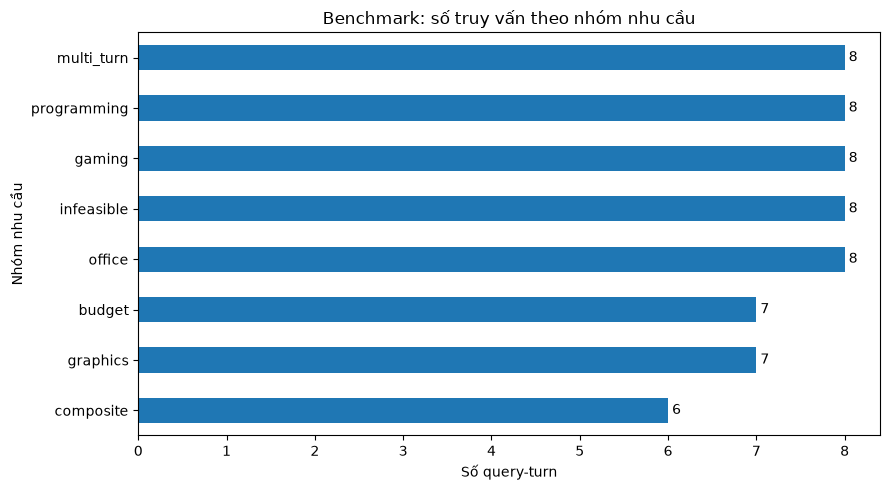

In [6]:
qcat = benchmark["category"].fillna("unknown").value_counts().sort_values(ascending=True)
fig, ax = plt.subplots()
qcat.plot(kind="barh", ax=ax)
ax.set_title("Benchmark: số truy vấn theo nhóm nhu cầu")
ax.set_xlabel("Số query-turn")
ax.set_ylabel("Nhóm nhu cầu")
for i, v in enumerate(qcat.values):
    ax.text(v, i, f" {v}", va="center")
plt.tight_layout()
plt.show()

## Biểu đồ 2 — Cơ cấu phạm vi đánh giá

**Ý nghĩa:** phân biệt ca độc lập chính, ca không khả thi và lượt hội thoại nhiều lượt. Các nhóm có thể có quan hệ lồng nhau theo thiết kế benchmark; vì vậy hãy đọc đây là phân bố theo nhãn `evaluation_scope`, không cộng chúng như các tập benchmark độc lập bổ sung.

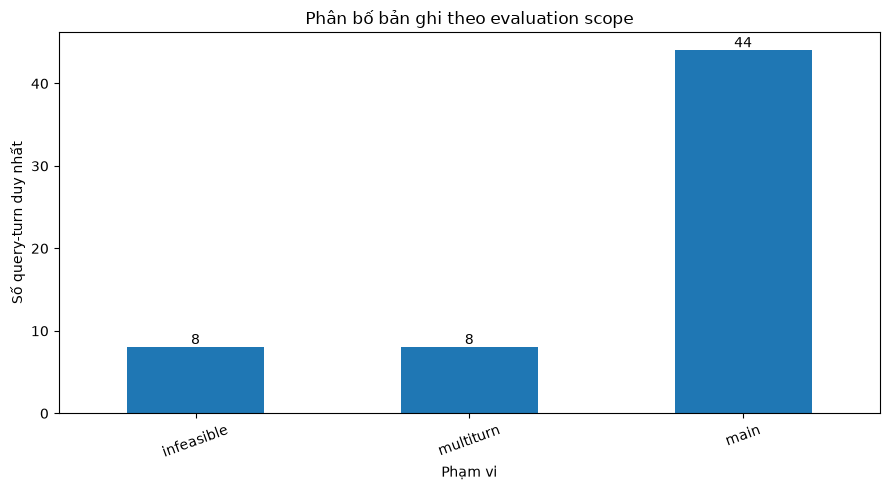

In [7]:
scope_counts = df.drop_duplicates(["query_id", "system"]).groupby("scope")["query_id"].nunique().sort_values()
fig, ax = plt.subplots()
scope_counts.plot(kind="bar", ax=ax)
ax.set_title("Phân bố bản ghi theo evaluation scope")
ax.set_xlabel("Phạm vi")
ax.set_ylabel("Số query-turn duy nhất")
ax.tick_params(axis="x", rotation=20)
for i, v in enumerate(scope_counts.values):
    ax.text(i, v, str(v), ha="center", va="bottom")
plt.tight_layout()
plt.show()

## Biểu đồ 3 — Tính khả thi dự kiến trong benchmark

**Ý nghĩa:** mô tả số ca được gán nhãn khả thi và không khả thi trước khi chạy. Đây là ground truth của benchmark; biểu đồ không nói hệ thống đã nhận diện đúng hay sai.

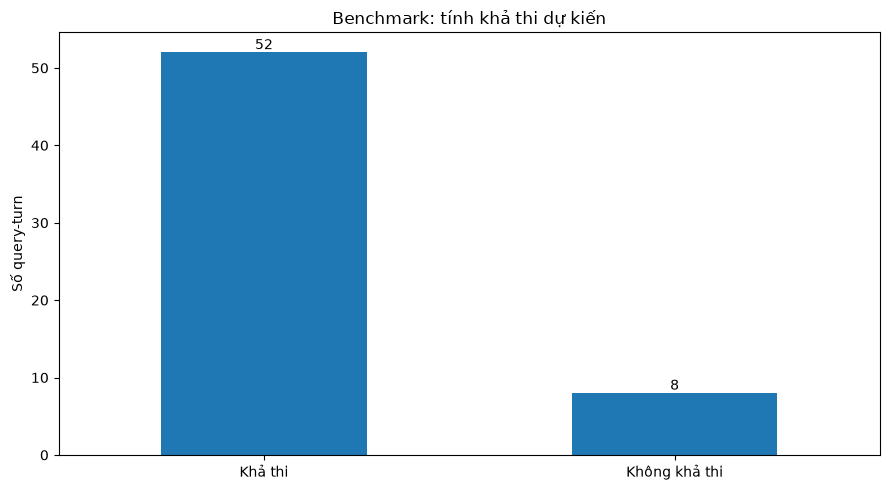

In [8]:
feas_counts = benchmark["expected_feasible"].apply(parse_bool).map({True: "Khả thi", False: "Không khả thi"}).value_counts()
fig, ax = plt.subplots()
feas_counts.plot(kind="bar", ax=ax)
ax.set_title("Benchmark: tính khả thi dự kiến")
ax.set_xlabel("")
ax.set_ylabel("Số query-turn")
ax.tick_params(axis="x", rotation=0)
for i, v in enumerate(feas_counts.values):
    ax.text(i, v, str(v), ha="center", va="bottom")
plt.tight_layout()
plt.show()

## RQ1 — Tính khả thi kỹ thuật

### Biểu đồ 4 — Tỉ lệ trích xuất chính xác từng phần yêu cầu

**Ý nghĩa:** đo mức khớp chính xác giữa kết quả NLU của Hybrid và ground truth đối với tags, constraints, preferences và toàn bộ RequirementSet. Exact match nghiêm ngặt: chỉ cần một thành phần khác là trường hợp đó không được tính đúng hoàn toàn.

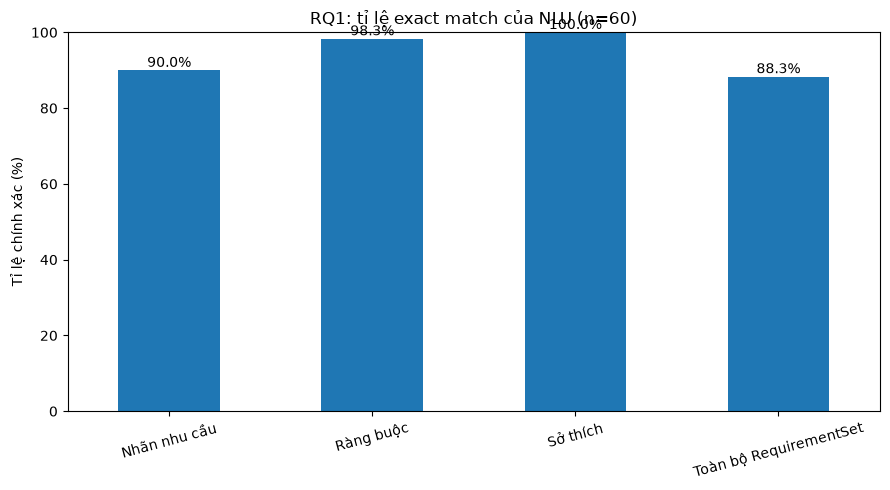

In [9]:
def norm_value(v):
    if isinstance(v, (bool, np.bool_)):
        return ("bool", bool(v))
    if isinstance(v, (int, float, np.integer, np.floating)) and not isinstance(v, (bool, np.bool_)):
        return ("num", round(float(v), 6))
    return ("str", str(v).strip().lower())

def as_list(v):
    if isinstance(v, list):
        return v
    return parse_json_cell(v, [])

def tags_set(req):
    return set(str(x) for x in (req or {}).get("required_tags", []) or [])

def constraints_set(req):
    out = set()
    for c in (req or {}).get("constraints", []) or []:
        out.add((str(c.get("field")), str(c.get("operator")), norm_value(c.get("value")),
                 str(c.get("type", "hard"))))
    return out

def preferences_set(req):
    return {(str(p.get("field")), str(p.get("direction")))
            for p in (req or {}).get("preferences", []) or []}

rq1_rows = []
for r in hybrid.to_dict("records"):
    gt = r.get("expected_requirements")
    pred = r.get("parsed_requirements")
    if not isinstance(gt, dict):
        continue
    gt_tags, pred_tags = tags_set(gt), tags_set(pred or {})
    gt_cons, pred_cons = constraints_set(gt), constraints_set(pred or {})
    gt_prefs, pred_prefs = preferences_set(gt), preferences_set(pred or {})
    rq1_rows.append({
        "query_id": r["query_id"], "category": r.get("category", "unknown"),
        "scope": r.get("evaluation_scope", "unknown"),
        "tags_exact": gt_tags == pred_tags,
        "constraints_exact": gt_cons == pred_cons,
        "preferences_exact": gt_prefs == pred_prefs,
        "full_requirement_exact": (gt_tags == pred_tags and gt_cons == pred_cons and gt_prefs == pred_prefs),
        "tag_tp": len(gt_tags & pred_tags), "tag_pred_n": len(pred_tags), "tag_gt_n": len(gt_tags),
        "constraint_tp": len(gt_cons & pred_cons), "constraint_pred_n": len(pred_cons), "constraint_gt_n": len(gt_cons),
    })
rq1 = pd.DataFrame(rq1_rows)
if rq1.empty:
    print("Không có dữ liệu RequirementSet phù hợp để tính RQ1.")
else:
    exact_cols = ["tags_exact", "constraints_exact", "preferences_exact", "full_requirement_exact"]
    exact_rates = rq1[exact_cols].mean().rename({
        "tags_exact": "Nhãn nhu cầu",
        "constraints_exact": "Ràng buộc",
        "preferences_exact": "Sở thích",
        "full_requirement_exact": "Toàn bộ RequirementSet"
    })
    fig, ax = plt.subplots()
    (exact_rates * 100).plot(kind="bar", ax=ax)
    ax.set_ylim(0, 100)
    ax.set_title(f"RQ1: tỉ lệ exact match của NLU (n={len(rq1)})")
    ax.set_ylabel("Tỉ lệ chính xác (%)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
    for i, v in enumerate(exact_rates.values * 100):
        ax.text(i, v, f"{v:.1f}%", ha="center", va="bottom")
    plt.tight_layout()
    plt.show()

### Biểu đồ 5 — Precision, Recall và F1 của trích xuất nhãn và ràng buộc

**Ý nghĩa:** exact match cho biết cả tập có khớp hoàn toàn hay không; Precision/Recall/F1 cho biết mức khớp từng phần. Precision thấp có thể phản ánh trích xuất thừa; Recall thấp có thể phản ánh bỏ sót. Hai metric này được tính từ tập nhãn/ràng buộc đã chuẩn hóa.

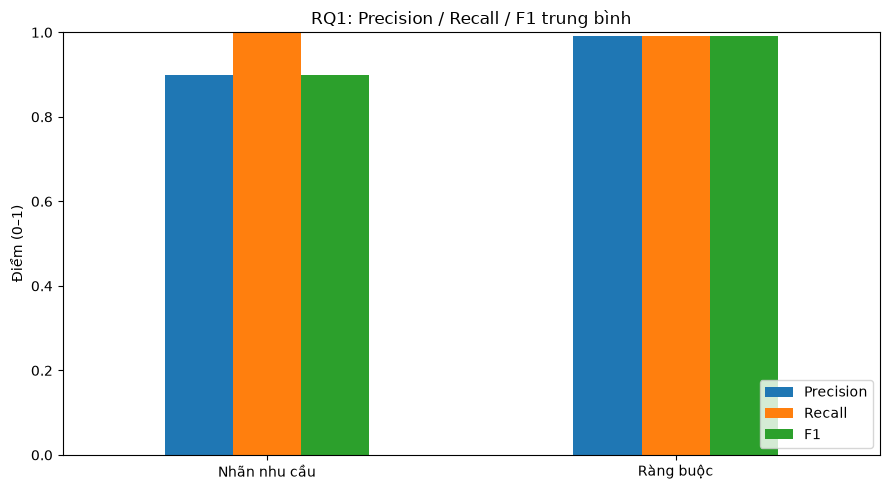

In [10]:
def prf(tp, pred_n, gt_n):
    precision = tp / pred_n if pred_n else (1.0 if gt_n == 0 else 0.0)
    recall = tp / gt_n if gt_n else 1.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return precision, recall, f1

metric_rows = []
for label, tp_col, pred_col, gt_col in [
    ("Nhãn nhu cầu", "tag_tp", "tag_pred_n", "tag_gt_n"),
    ("Ràng buộc", "constraint_tp", "constraint_pred_n", "constraint_gt_n")
]:
    scores = [prf(r[tp_col], r[pred_col], r[gt_col]) for _, r in rq1.iterrows()]
    metric_rows.append({"Loại": label, "Precision": np.mean([x[0] for x in scores]),
                        "Recall": np.mean([x[1] for x in scores]), "F1": np.mean([x[2] for x in scores])})
prf_df = pd.DataFrame(metric_rows).set_index("Loại")
fig, ax = plt.subplots()
prf_df.plot(kind="bar", ax=ax)
ax.set_ylim(0, 1)
ax.set_title("RQ1: Precision / Recall / F1 trung bình")
ax.set_ylabel("Điểm (0–1)")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Biểu đồ 6 — Exact match theo nhóm nhu cầu

**Ý nghĩa:** giúp phát hiện nhóm truy vấn mà bộ trích xuất hoạt động tốt hoặc kém hơn. Do số mẫu mỗi nhóm có thể nhỏ, hãy luôn xem thêm số lượng mẫu và không suy rộng kết luận cho mọi truy vấn tiếng Việt.

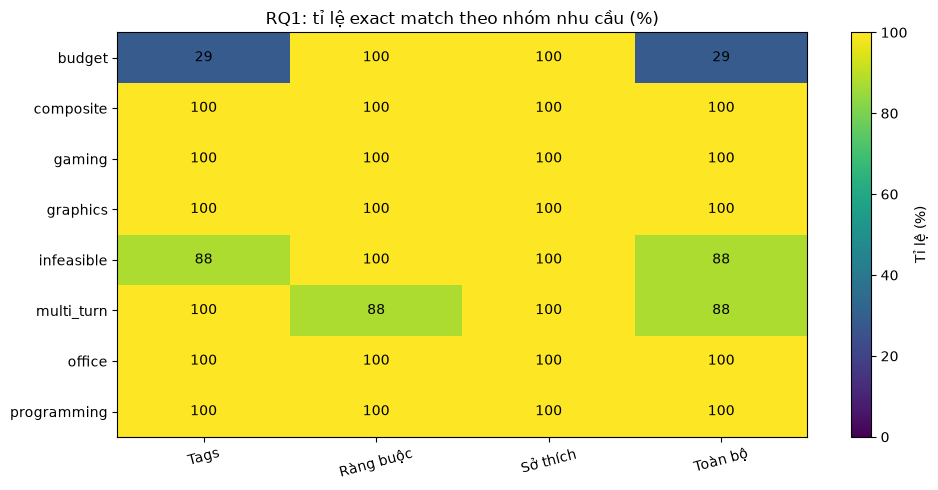

In [11]:
if not rq1.empty:
    by_cat = rq1.groupby("category")[["tags_exact", "constraints_exact", "preferences_exact", "full_requirement_exact"]].mean() * 100
    by_cat = by_cat.rename(columns={"tags_exact": "Tags", "constraints_exact": "Ràng buộc",
                                    "preferences_exact": "Sở thích", "full_requirement_exact": "Toàn bộ"})
    fig, ax = plt.subplots(figsize=(10, 5))
    im = ax.imshow(by_cat.values, aspect="auto", vmin=0, vmax=100)
    ax.set_xticks(range(len(by_cat.columns)), labels=by_cat.columns, rotation=15)
    ax.set_yticks(range(len(by_cat.index)), labels=by_cat.index)
    ax.set_title("RQ1: tỉ lệ exact match theo nhóm nhu cầu (%)")
    for i in range(by_cat.shape[0]):
        for j in range(by_cat.shape[1]):
            ax.text(j, i, f"{by_cat.iloc[i, j]:.0f}", ha="center", va="center")
    fig.colorbar(im, ax=ax, label="Tỉ lệ (%)")
    plt.tight_layout()
    plt.show()

### Biểu đồ 7 — Ma trận nhầm lẫn khi nhận diện tính khả thi

**Ý nghĩa:** so sánh tính khả thi ground truth với việc Hybrid có tìm thấy ứng viên hay không. Trong biểu đồ này, `candidate_count > 0` được dùng làm chỉ báo khả thi thực tế của bước lọc ứng viên. Đây là phép đo dựa trên số ứng viên, không thay thế kiểm tra độc lập toàn bộ lời giải.

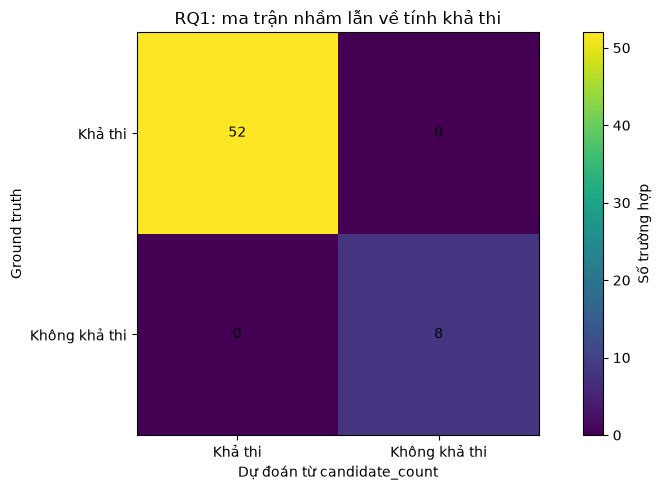

Accuracy theo chỉ báo candidate_count: 1.0


In [12]:
h = hybrid.copy()
h["predicted_feasible"] = pd.to_numeric(h.get("candidate_count"), errors="coerce") > 0
h["expected_feasible_label"] = h["expected_feasible_bool"].map({True: "Khả thi", False: "Không khả thi"})
h["predicted_feasible_label"] = h["predicted_feasible"].map({True: "Khả thi", False: "Không khả thi"})
cm = pd.crosstab(h["expected_feasible_label"], h["predicted_feasible_label"]).reindex(
    index=["Khả thi", "Không khả thi"], columns=["Khả thi", "Không khả thi"], fill_value=0)
fig, ax = plt.subplots()
im = ax.imshow(cm.values)
ax.set_xticks([0, 1], labels=cm.columns)
ax.set_yticks([0, 1], labels=cm.index)
ax.set_xlabel("Dự đoán từ candidate_count")
ax.set_ylabel("Ground truth")
ax.set_title("RQ1: ma trận nhầm lẫn về tính khả thi")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm.iloc[i, j]), ha="center", va="center")
fig.colorbar(im, ax=ax, label="Số trường hợp")
plt.tight_layout()
plt.show()
print("Accuracy theo chỉ báo candidate_count:", round((h["predicted_feasible"] == h["expected_feasible_bool"]).mean(), 3))

### Biểu đồ 8 — Số ứng viên thực tế so với ground truth

**Ý nghĩa:** điểm nằm gần đường chéo (y=x) cho biết số ứng viên khớp ground truth. Nếu sai lệch lớn, cần xem lại chuẩn hóa yêu cầu hoặc quy tắc lọc catalog. Các điểm chồng lên nhau là bình thường khi nhiều truy vấn có cùng số ứng viên.

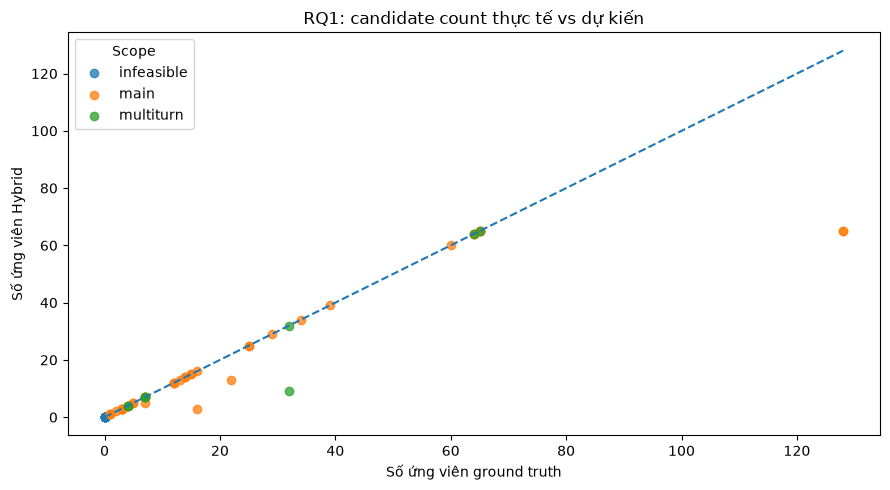

In [13]:
cand = hybrid.copy()
cand["candidate_count"] = pd.to_numeric(cand["candidate_count"], errors="coerce")
cand["expected_candidate_count"] = pd.to_numeric(cand["expected_candidate_count"], errors="coerce")
cand = cand.dropna(subset=["candidate_count", "expected_candidate_count"])
fig, ax = plt.subplots()
for scope, group in cand.groupby("evaluation_scope"):
    ax.scatter(group["expected_candidate_count"], group["candidate_count"], label=str(scope), alpha=0.75)
if not cand.empty:
    lo = min(cand["expected_candidate_count"].min(), cand["candidate_count"].min())
    hi = max(cand["expected_candidate_count"].max(), cand["candidate_count"].max())
    ax.plot([lo, hi], [lo, hi], linestyle="--")
ax.set_title("RQ1: candidate count thực tế vs dự kiến")
ax.set_xlabel("Số ứng viên ground truth")
ax.set_ylabel("Số ứng viên Hybrid")
ax.legend(title="Scope")
plt.tight_layout()
plt.show()

### Biểu đồ 9 — Phân bố sai lệch số ứng viên

**Ý nghĩa:** sai lệch được tính bằng số ứng viên Hybrid trừ số ứng viên dự kiến. Giá trị 0 là khớp chính xác; số dương là hệ thống giữ lại nhiều ứng viên hơn dự kiến, số âm là ít hơn. Sai lệch số lượng không tự nói lên chất lượng sản phẩm được chọn.

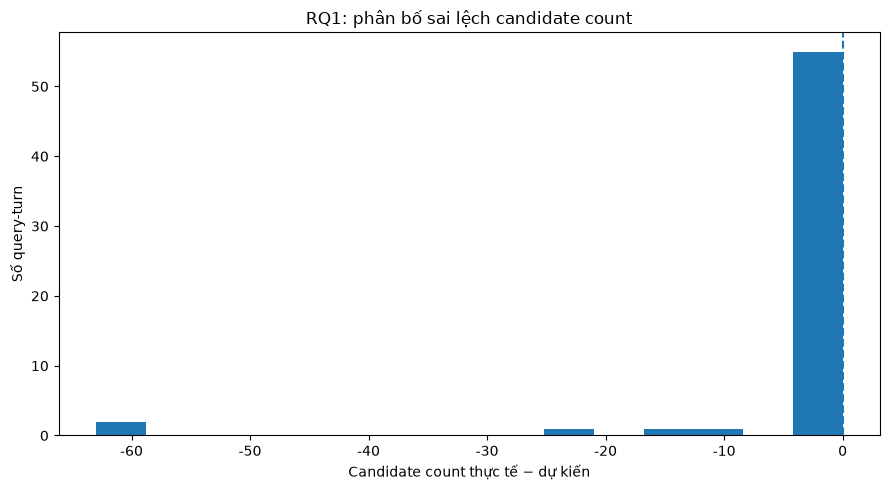

,query_id,evaluation_scope,expected_candidate_count,candidate_count,candidate_count_error
69,B04,main,128,65.0,-63.0
63,B01,main,128,65.0,-63.0
106,M01-T3,multiturn,32,9.0,-23.0
75,B07,main,16,3.0,-13.0
67,B03,main,22,13.0,-9.0
65,B02,main,7,5.0,-2.0
9,O05,main,12,12.0,0.0
11,O06,main,16,16.0,0.0
1,O01,main,65,65.0,0.0
3,O02,main,5,5.0,0.0


In [14]:
cand["candidate_count_error"] = cand["candidate_count"] - cand["expected_candidate_count"]
fig, ax = plt.subplots()
ax.hist(cand["candidate_count_error"], bins=15)
ax.axvline(0, linestyle="--")
ax.set_title("RQ1: phân bố sai lệch candidate count")
ax.set_xlabel("Candidate count thực tế − dự kiến")
ax.set_ylabel("Số query-turn")
plt.tight_layout()
plt.show()
display(cand[["query_id", "evaluation_scope", "expected_candidate_count", "candidate_count", "candidate_count_error"]]
        .sort_values("candidate_count_error", key=lambda s: s.abs(), ascending=False).head(10))

### Biểu đồ 10 — Độ chính xác thao tác ngữ cảnh ở hội thoại nhiều lượt

**Ý nghĩa:** kiểm tra ADD, UPDATE và REPLACE trên 8 lượt multi-turn. Mẫu nhỏ nên nên trình bày cả ma trận nhầm lẫn và bảng từng trường hợp; không nên khái quát kết quả này thành độ chính xác hội thoại nói chung.

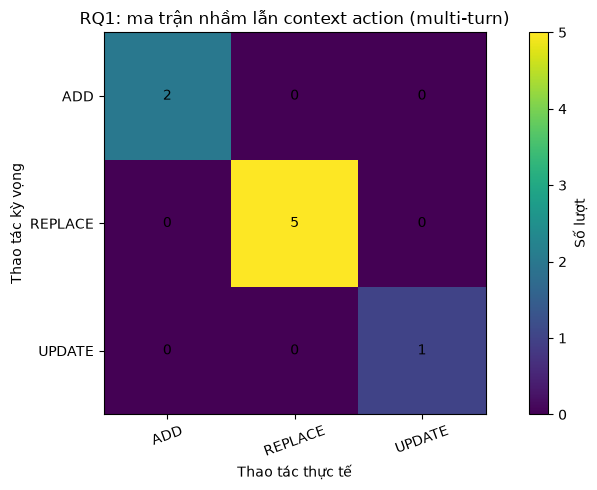

Context-action accuracy: 1.0


,query_id,raw_query,expected_context_action,context_action
104,M01-T1,Tôi cần laptop lập trình tầm 20 triệu.,REPLACE,REPLACE
105,M01-T2,Ngoài ra tôi cần máy dưới 1.5kg.,ADD,ADD
106,M01-T3,Thôi nâng ngân sách lên 25 triệu.,UPDATE,UPDATE
107,M02-T1,Tôi muốn laptop gaming khoảng 25 triệu có RTX 4060.,REPLACE,REPLACE
108,M02-T2,Ngoài ra pin ít nhất 5 giờ.,ADD,ADD
109,M02-T3,Tư vấn laptop văn phòng giá rẻ tầm 15 triệu.,REPLACE,REPLACE
110,M03-T1,"Tìm laptop văn phòng dưới 20 triệu, mỏng nhẹ.",REPLACE,REPLACE
111,M03-T2,Thôi đổi sang laptop đồ họa dưới 30 triệu có card rời.,REPLACE,REPLACE


In [15]:
mt = multiturn.copy()
if not mt.empty and "context_action" in mt.columns:
    mt["expected_context_action"] = mt["expected_context_action"].fillna("UNKNOWN").astype(str)
    mt["context_action"] = mt["context_action"].fillna("UNKNOWN").astype(str)
    action_cm = pd.crosstab(mt["expected_context_action"], mt["context_action"])
    labels = sorted(set(action_cm.index) | set(action_cm.columns))
    action_cm = action_cm.reindex(index=labels, columns=labels, fill_value=0)
    fig, ax = plt.subplots()
    im = ax.imshow(action_cm.values)
    ax.set_xticks(range(len(labels)), labels=labels, rotation=20)
    ax.set_yticks(range(len(labels)), labels=labels)
    ax.set_xlabel("Thao tác thực tế")
    ax.set_ylabel("Thao tác kỳ vọng")
    ax.set_title("RQ1: ma trận nhầm lẫn context action (multi-turn)")
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, str(action_cm.iloc[i, j]), ha="center", va="center")
    fig.colorbar(im, ax=ax, label="Số lượt")
    plt.tight_layout()
    plt.show()
    print("Context-action accuracy:", round((mt["context_action"] == mt["expected_context_action"]).mean(), 3))
    display(mt[["query_id", "raw_query", "expected_context_action", "context_action"]])
else:
    print("Không có bản ghi multi-turn hoặc trường context_action.")

### Biểu đồ 11 — Nguồn NLU được sử dụng

**Ý nghĩa:** cho biết số lượt Hybrid dùng Gemini kết hợp Regex hay rơi về Regex fallback. Đây là thống kê vận hành của parser; tỉ lệ fallback cao/thấp tự nó không chứng minh chất lượng trích xuất cao/thấp.

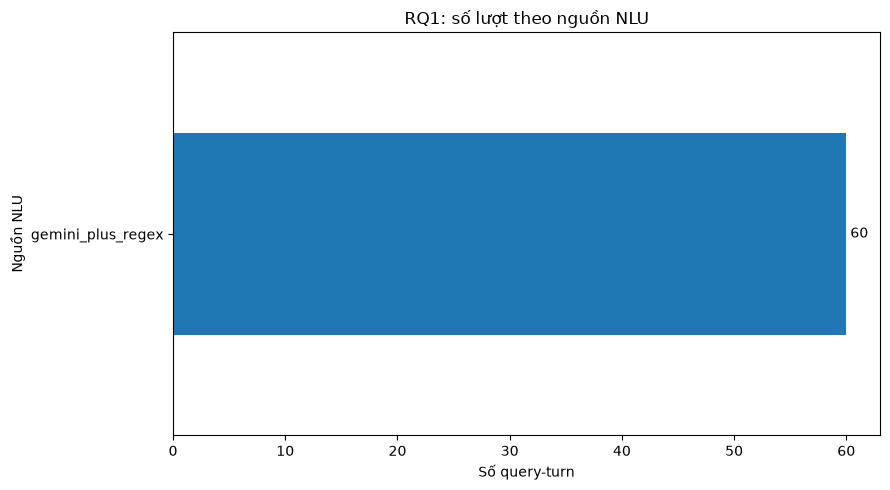

In [16]:
if "nlu_source" in hybrid.columns:
    source_counts = hybrid["nlu_source"].fillna("unknown").value_counts().sort_values()
    fig, ax = plt.subplots()
    source_counts.plot(kind="barh", ax=ax)
    ax.set_title("RQ1: số lượt theo nguồn NLU")
    ax.set_xlabel("Số query-turn")
    ax.set_ylabel("Nguồn NLU")
    for i, v in enumerate(source_counts.values):
        ax.text(v, i, f" {v}", va="center")
    plt.tight_layout()
    plt.show()
else:
    print("Dataset không có trường nlu_source.")

### Biểu đồ 12 — Trạng thái xử lý của Hybrid theo phạm vi

**Ý nghĩa:** phân biệt ca được giải tối ưu (`OPTIMAL`) với ca được trả về phương án nới lỏng (`RELAXED`). `RELAXED` không nên tự động gọi là lỗi: trong benchmark, các ca không khả thi được thiết kế để hệ thống đưa ra phương án gần nhất.

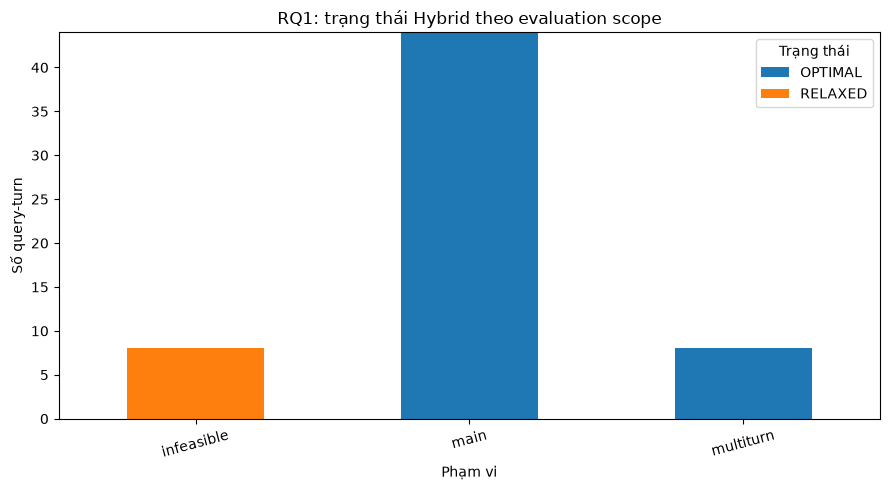

In [17]:
status_scope = pd.crosstab(hybrid["scope"], hybrid["status"])
fig, ax = plt.subplots()
status_scope.plot(kind="bar", stacked=True, ax=ax)
ax.set_title("RQ1: trạng thái Hybrid theo evaluation scope")
ax.set_xlabel("Phạm vi")
ax.set_ylabel("Số query-turn")
ax.tick_params(axis="x", rotation=15)
ax.legend(title="Trạng thái")
plt.tight_layout()
plt.show()

## RQ2 — Độ tin cậy của quyết định

### Biểu đồ 13 — Tỉ lệ thỏa mãn hard constraints theo cờ hệ thống ghi nhận

**Ý nghĩa:** đây là tỉ lệ trong các ca độc lập, khả thi và có giá trị `hard_constraint_satisfied` của Hybrid. Vì cột này do hệ thống ghi log, hãy gọi là **tỉ lệ theo cờ hệ thống**, không gọi là xác minh độc lập. Các trường hợp không có giá trị bị loại khỏi mẫu số.

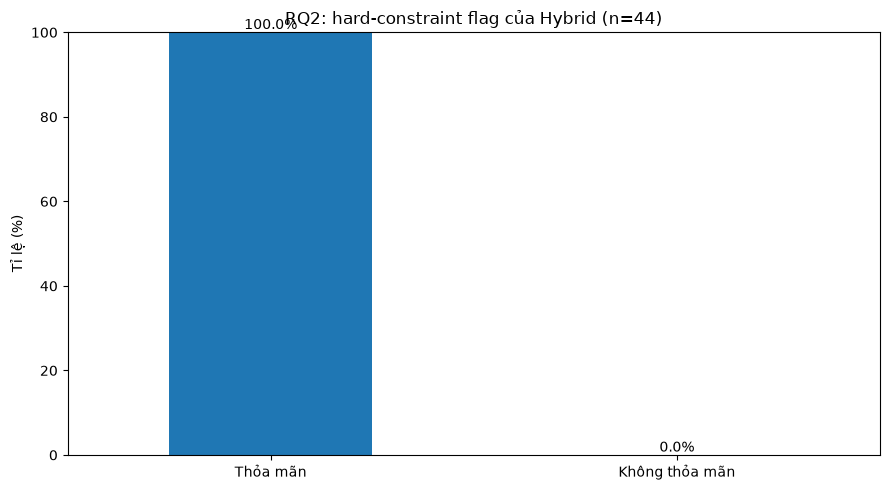

In [18]:
rq2_hybrid_feasible = hybrid[
    hybrid["scope"].ne("multiturn") &
    hybrid["expected_feasible_bool"].eq(True)
].copy()
if "hard_constraint_satisfied" in rq2_hybrid_feasible.columns:
    vals = rq2_hybrid_feasible["hard_constraint_satisfied"].dropna().map(parse_bool).dropna()
    if len(vals):
        rates = pd.Series({"Thỏa mãn": vals.eq(True).mean() * 100,
                           "Không thỏa mãn": vals.eq(False).mean() * 100})
        fig, ax = plt.subplots()
        rates.plot(kind="bar", ax=ax)
        ax.set_ylim(0, 100)
        ax.set_title(f"RQ2: hard-constraint flag của Hybrid (n={len(vals)})")
        ax.set_ylabel("Tỉ lệ (%)")
        ax.tick_params(axis="x", rotation=0)
        for i, v in enumerate(rates.values):
            ax.text(i, v, f"{v:.1f}%", ha="center", va="bottom")
        plt.tight_layout()
        plt.show()
    else:
        print("Không có hard_constraint_satisfied hợp lệ trong các ca khả thi.")
else:
    print("Dataset không có hard_constraint_satisfied.")

### Biểu đồ 14 — Phân bố số vi phạm soft constraint

**Ý nghĩa:** cho thấy số vi phạm ràng buộc mềm được ghi nhận trên mỗi ca khả thi của Hybrid. Đây là số liệu theo log nội bộ; nó không tương đương với kiểm tra catalog độc lập. Một vi phạm mềm có thể được chấp nhận nếu hệ thống đánh đổi để tăng utility, nhưng cần diễn giải đúng yêu cầu của benchmark.

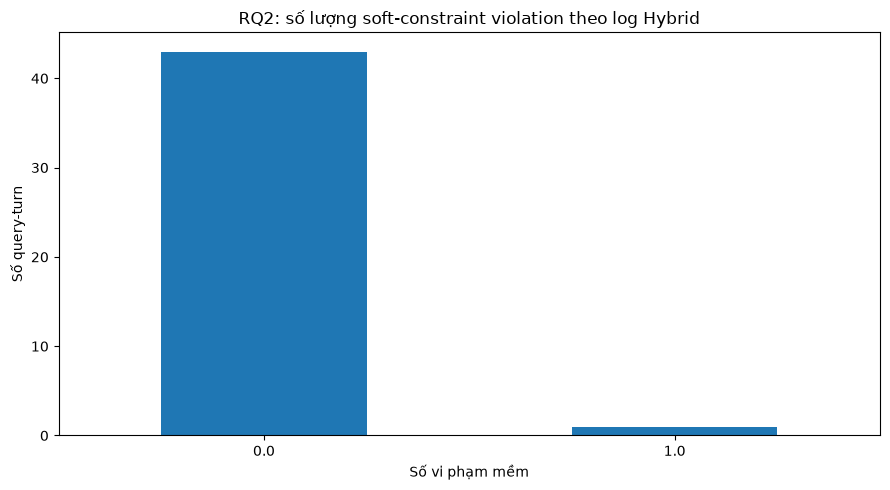

In [19]:
soft = rq2_hybrid_feasible.copy()
if "soft_violation_count" in soft.columns:
    soft_counts = soft["soft_violation_count"].dropna().value_counts().sort_index()
    if len(soft_counts):
        fig, ax = plt.subplots()
        soft_counts.plot(kind="bar", ax=ax)
        ax.set_title("RQ2: số lượng soft-constraint violation theo log Hybrid")
        ax.set_xlabel("Số vi phạm mềm")
        ax.set_ylabel("Số query-turn")
        ax.tick_params(axis="x", rotation=0)
        plt.tight_layout()
        plt.show()
    else:
        print("Không có soft_violation_count hợp lệ.")
else:
    print("Dataset không có soft_violation_count.")

### Biểu đồ 15 — Tỉ lệ vi phạm soft constraint theo log Hybrid

**Ý nghĩa:** tóm tắt tỉ lệ ca có ít nhất một vi phạm mềm, trong số ca khả thi có trường dữ liệu. Không nên so sánh trực tiếp với hard-constraint satisfaction: hai metric đo hai loại yêu cầu khác nhau.

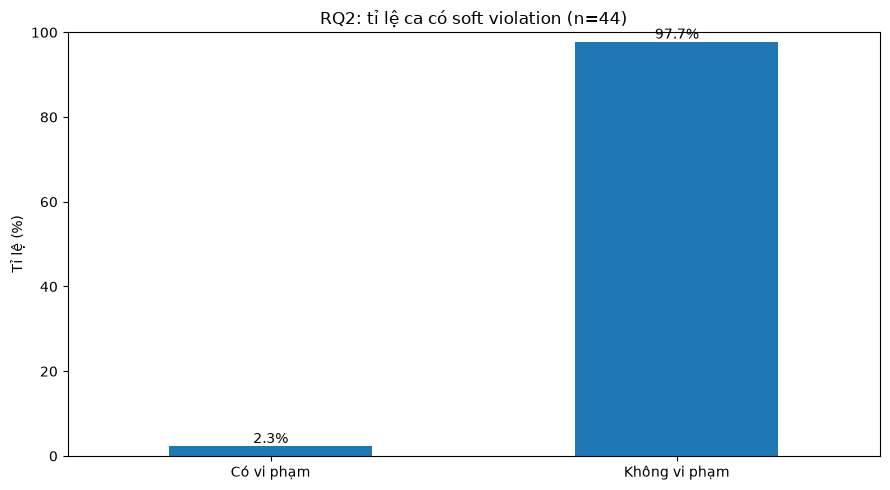

In [20]:
if "has_soft_violation" in soft.columns:
    sv = soft["has_soft_violation"].dropna().map(parse_bool).dropna()
    if len(sv):
        pct = pd.Series({"Có vi phạm": sv.eq(True).mean() * 100,
                         "Không vi phạm": sv.eq(False).mean() * 100})
        fig, ax = plt.subplots()
        pct.plot(kind="bar", ax=ax)
        ax.set_ylim(0, 100)
        ax.set_title(f"RQ2: tỉ lệ ca có soft violation (n={len(sv)})")
        ax.set_ylabel("Tỉ lệ (%)")
        ax.tick_params(axis="x", rotation=0)
        for i, v in enumerate(pct.values):
            ax.text(i, v, f"{v:.1f}%", ha="center", va="bottom")
        plt.tight_layout()
        plt.show()

### Biểu đồ 16 — Trạng thái của hệ thống theo tính khả thi ground truth

**Ý nghĩa:** kiểm tra xem ca được gán không khả thi có thường dẫn đến `RELAXED` và ca khả thi có thường dẫn đến `OPTIMAL` hay không. Đây là mô tả trạng thái đầu ra, không thay thế metric feasibility-detection độc lập.

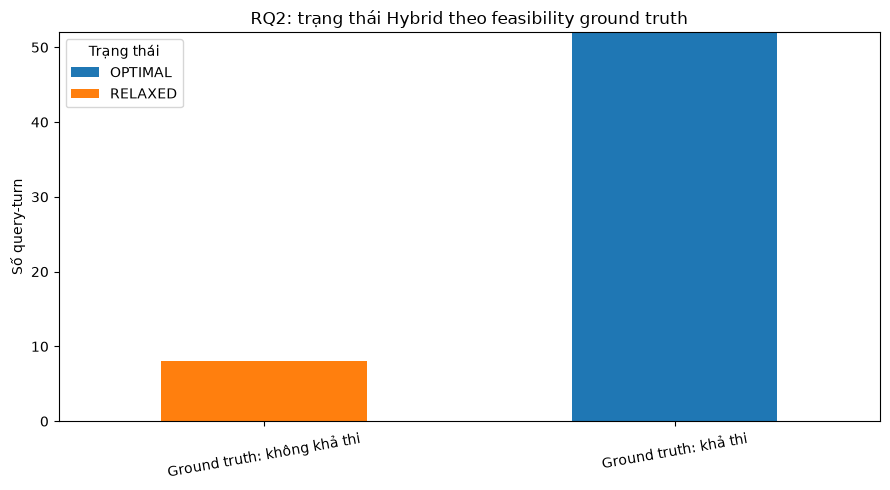

In [21]:
fig, ax = plt.subplots()
status_feas = pd.crosstab(hybrid["expected_feasible_bool"].map({True: "Ground truth: khả thi", False: "Ground truth: không khả thi"}),
                          hybrid["status"])
status_feas.plot(kind="bar", stacked=True, ax=ax)
ax.set_title("RQ2: trạng thái Hybrid theo feasibility ground truth")
ax.set_xlabel("")
ax.set_ylabel("Số query-turn")
ax.tick_params(axis="x", rotation=10)
ax.legend(title="Trạng thái")
plt.tight_layout()
plt.show()

### Biểu đồ 17 — Xác minh độc lập đối với đề xuất LLM-only

**Ý nghĩa:** biểu đồ dùng file `external_verification_llm_only.csv`, ghi lại kết quả xác minh ngoài cho các đề xuất LLM-only. Đây chỉ là kết quả xác minh của baseline LLM-only; không được suy ra rằng Hybrid có cùng tỉ lệ. `EXACT_MODEL_NOT_CONFIRMED` hoặc `OUT_OF_CATALOG` không đồng nghĩa với hallucination nếu chưa xác minh thêm.

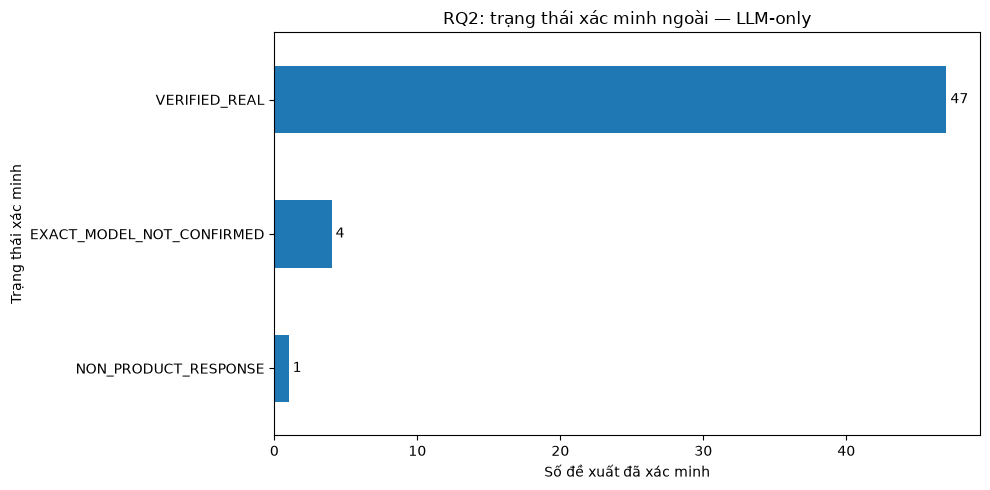

In [22]:
if not verification.empty and "verification_status" in verification.columns:
    vc = verification["verification_status"].fillna("UNKNOWN").value_counts().sort_values()
    fig, ax = plt.subplots(figsize=(10, 5))
    vc.plot(kind="barh", ax=ax)
    ax.set_title("RQ2: trạng thái xác minh ngoài — LLM-only")
    ax.set_xlabel("Số đề xuất đã xác minh")
    ax.set_ylabel("Trạng thái xác minh")
    for i, v in enumerate(vc.values):
        ax.text(v, i, f" {v}", va="center")
    plt.tight_layout()
    plt.show()
else:
    print("Không có external_verification_llm_only.csv hoặc trường verification_status.")

### Biểu đồ 18 — Trạng thái kiểm tra thông số của LLM-only

**Ý nghĩa:** tách việc sản phẩm có tồn tại khỏi việc thông số được nêu có sai lệch đáng kể hay không. Đây là lý do không nên dùng một nhãn “hallucination” duy nhất để gộp mọi trường hợp sản phẩm không khớp catalog.

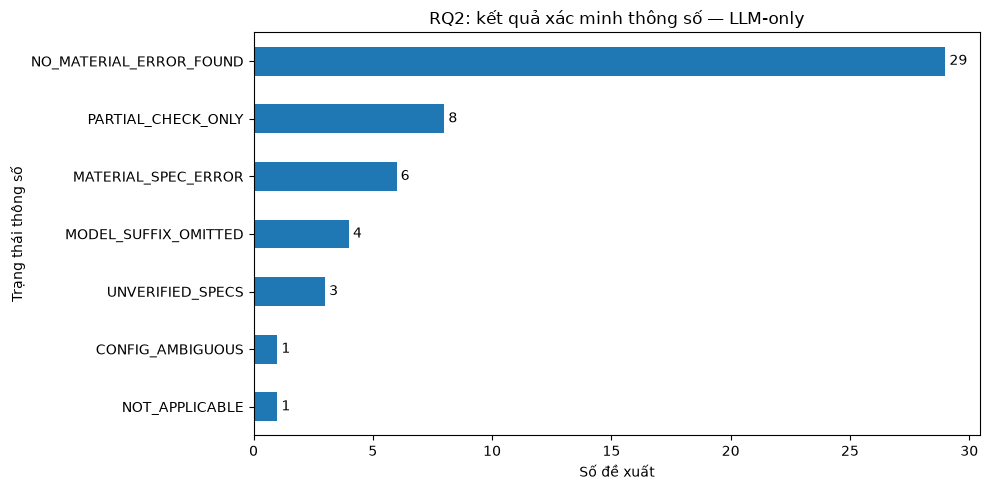

In [23]:
if not verification.empty and "spec_status" in verification.columns:
    sc = verification["spec_status"].fillna("UNKNOWN").value_counts().sort_values()
    fig, ax = plt.subplots(figsize=(10, 5))
    sc.plot(kind="barh", ax=ax)
    ax.set_title("RQ2: kết quả xác minh thông số — LLM-only")
    ax.set_xlabel("Số đề xuất")
    ax.set_ylabel("Trạng thái thông số")
    for i, v in enumerate(sc.values):
        ax.text(v, i, f" {v}", va="center")
    plt.tight_layout()
    plt.show()

### Biểu đồ 19 — Độ tin cậy của người xác minh theo trạng thái

**Ý nghĩa:** biểu đồ chéo cho biết các trạng thái xác minh được gán mức confidence nào. Dùng để minh bạch chất lượng chứng cứ thủ công; không phải độ tin cậy xác suất đã được hiệu chuẩn.

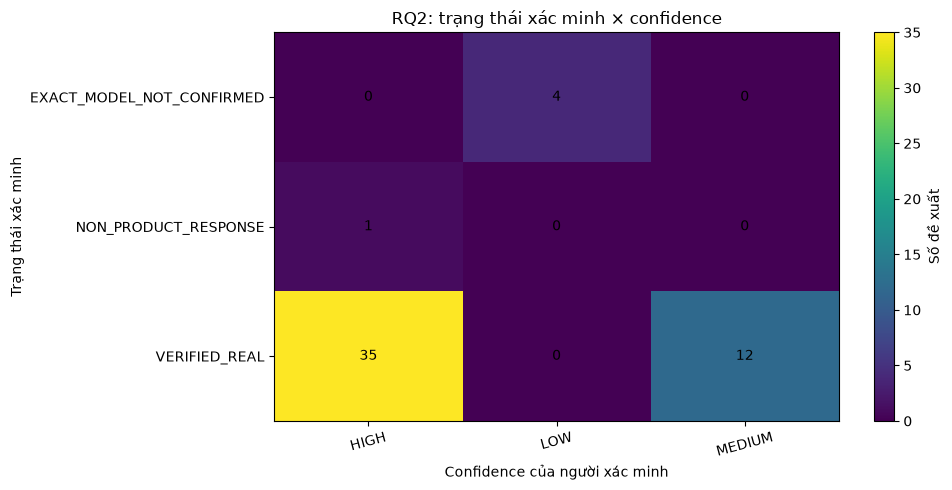

In [24]:
if not verification.empty and {"verification_status", "confidence"}.issubset(verification.columns):
    tab = pd.crosstab(verification["verification_status"].fillna("UNKNOWN"),
                      verification["confidence"].fillna("UNKNOWN"))
    fig, ax = plt.subplots(figsize=(10, 5))
    im = ax.imshow(tab.values, aspect="auto")
    ax.set_xticks(range(len(tab.columns)), labels=tab.columns, rotation=15)
    ax.set_yticks(range(len(tab.index)), labels=tab.index)
    ax.set_title("RQ2: trạng thái xác minh × confidence")
    ax.set_xlabel("Confidence của người xác minh")
    ax.set_ylabel("Trạng thái xác minh")
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            ax.text(j, i, str(tab.iloc[i, j]), ha="center", va="center")
    fig.colorbar(im, ax=ax, label="Số đề xuất")
    plt.tight_layout()
    plt.show()

### Biểu đồ 20 — Đánh giá độc lập từ `evaluated_results.csv` (nếu có)

**Ý nghĩa:** nếu đã chạy `experiments/analyze_results.py` với catalog đã xử lý và tạo `experiments/results/evaluated_results.csv`, phần này vẽ các chỉ số độc lập: sản phẩm khớp catalog, thỏa mãn hard constraints theo catalog và vi phạm soft constraints. Nếu file không tồn tại, notebook không tự thay bằng cờ của solver.

Đã nạp evaluator độc lập: experiments\results\evaluated_results.csv | n = 112


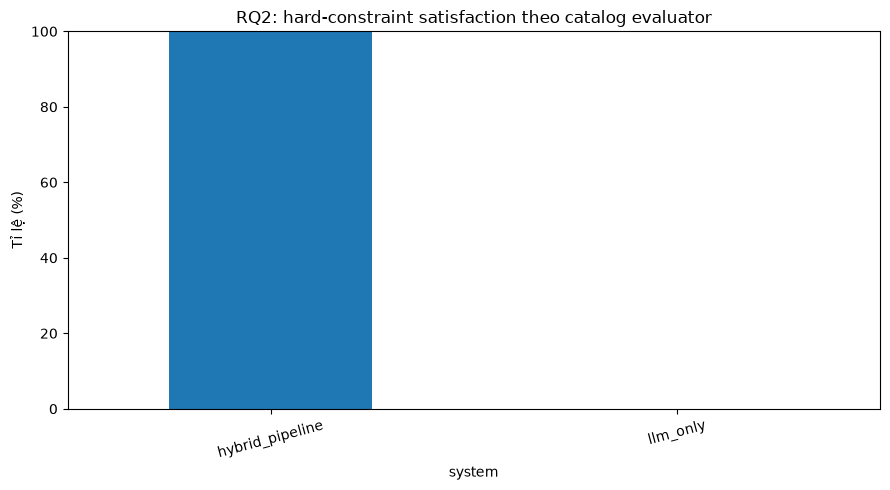

In [25]:
evaluated_path = EXP / "results" / "evaluated_results.csv"
if evaluated_path.exists():
    ev = pd.read_csv(evaluated_path)
    print("Đã nạp evaluator độc lập:", evaluated_path.relative_to(ROOT), "| n =", len(ev))
    if "system" in ev.columns:
        if "recommendation_class" in ev.columns:
            display(pd.crosstab(ev["system"], ev["recommendation_class"]))
            sub = ev[ev["system"].isin(["llm_only", "hybrid_pipeline", "catalog_grounded_llm"])].copy()
            if not sub.empty:
                rate = sub.assign(valid=sub["recommendation_class"].eq("CATALOG_VALID")).groupby("system")["valid"].mean() * 100
                fig, ax = plt.subplots()
                rate.plot(kind="bar", ax=ax)
                ax.set_ylim(0, 100)
                ax.set_title("RQ2: tỉ lệ đề xuất khớp catalog theo evaluator độc lập")
                ax.set_ylabel("Tỉ lệ trong các bản ghi của hệ thống (%)")
                ax.tick_params(axis="x", rotation=15)
                plt.tight_layout()
                plt.show()
        if "independent_hard_constraint_satisfied" in ev.columns:
            ev_feasible = ev[ev["expected_feasible"].apply(parse_bool).eq(True)].copy()
            ev_feasible["independent_hard_constraint_satisfied"] = ev_feasible["independent_hard_constraint_satisfied"].apply(parse_bool)
            independent_rates = ev_feasible.dropna(subset=["independent_hard_constraint_satisfied"]).groupby("system")["independent_hard_constraint_satisfied"].mean() * 100
            if len(independent_rates):
                fig, ax = plt.subplots()
                independent_rates.plot(kind="bar", ax=ax)
                ax.set_ylim(0, 100)
                ax.set_title("RQ2: hard-constraint satisfaction theo catalog evaluator")
                ax.set_ylabel("Tỉ lệ (%)")
                ax.tick_params(axis="x", rotation=15)
                plt.tight_layout()
                plt.show()
        if "catalog_explicit_hard_constraint_status" in ev.columns:
            display(pd.crosstab(ev["system"], ev["catalog_explicit_hard_constraint_status"]))
else:
    print("Chưa có evaluated_results.csv. Bỏ qua biểu đồ đánh giá độc lập theo catalog.")
    print("Để tạo file, cần có data/processed/laptop_dataset_scored.csv hoặc laptop_dataset_tagged.csv,")
    print("sau đó chạy experiments/analyze_results.py theo hướng dẫn trong file đó.")

## RQ3 — Khả thi vận hành

### Biểu đồ 21 — Phân bố latency theo hệ thống

**Ý nghĩa:** so sánh thời gian phản hồi đầu-cuối. Dùng trục log để outlier lớn không làm các giá trị còn lại khó nhìn; outlier vẫn được giữ lại vì có thể phản ánh retry, rate limit hoặc fallback. Đơn vị được đổi sang giây.

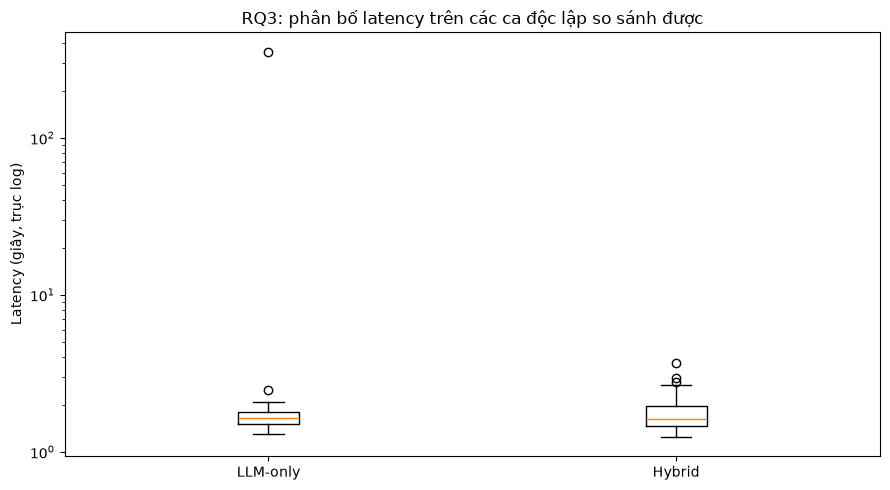

In [26]:
lat = independent.dropna(subset=["latency_s"]).copy()
lat = lat[lat["latency_s"] > 0]
if not lat.empty:
    groups = [g["latency_s"].values for _, g in lat.groupby("system_label", sort=False)]
    labels = [name for name, _ in lat.groupby("system_label", sort=False)]
    fig, ax = plt.subplots()
    ax.boxplot(groups, tick_labels=labels, showfliers=True)
    ax.set_yscale("log")
    ax.set_title("RQ3: phân bố latency trên các ca độc lập so sánh được")
    ax.set_ylabel("Latency (giây, trục log)")
    ax.set_xlabel("")
    plt.tight_layout()
    plt.show()

### Biểu đồ 22 — Mean, median và p95 latency

**Ý nghĩa:** mean nhạy với outlier; median mô tả ca điển hình hơn; p95 thể hiện phần đuôi chậm. Báo cáo cả ba giúp tránh kết luận dựa trên trung bình đơn lẻ.

,mean,median,p95
system_label,,,
Hybrid,1.771,1.617,2.723
LLM-only,8.444,1.635,2.031


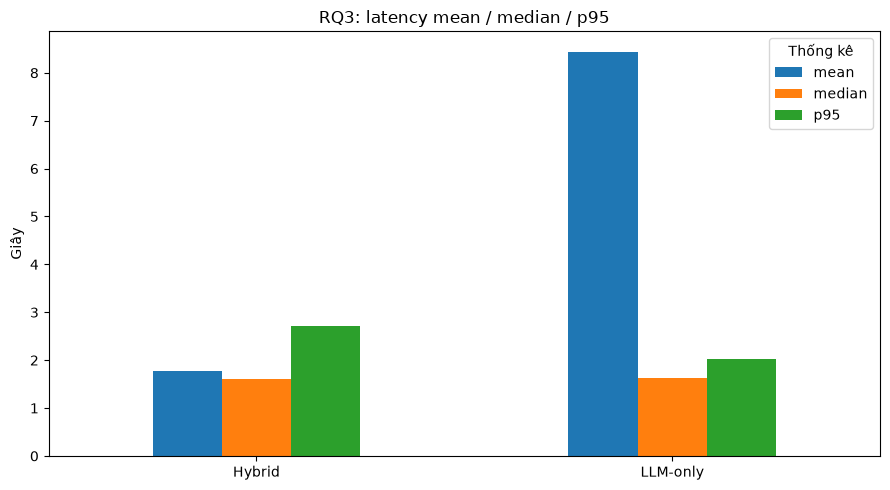

In [27]:
lat_summary = lat.groupby("system_label")["latency_s"].agg(
    mean="mean", median="median",
    p95=lambda s: s.quantile(0.95)
)
display(lat_summary.round(3))
fig, ax = plt.subplots()
lat_summary.plot(kind="bar", ax=ax)
ax.set_title("RQ3: latency mean / median / p95")
ax.set_ylabel("Giây")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Thống kê")
plt.tight_layout()
plt.show()

### Biểu đồ 23 — Chênh lệch latency theo từng query đã ghép cặp

**Ý nghĩa:** với mỗi query độc lập có kết quả của cả hai hệ thống, tính `Hybrid − LLM-only`. Giá trị âm nghĩa là Hybrid nhanh hơn ở query đó; giá trị dương nghĩa là chậm hơn. Ghép cặp giúp giảm ảnh hưởng do độ khó khác nhau giữa các truy vấn.

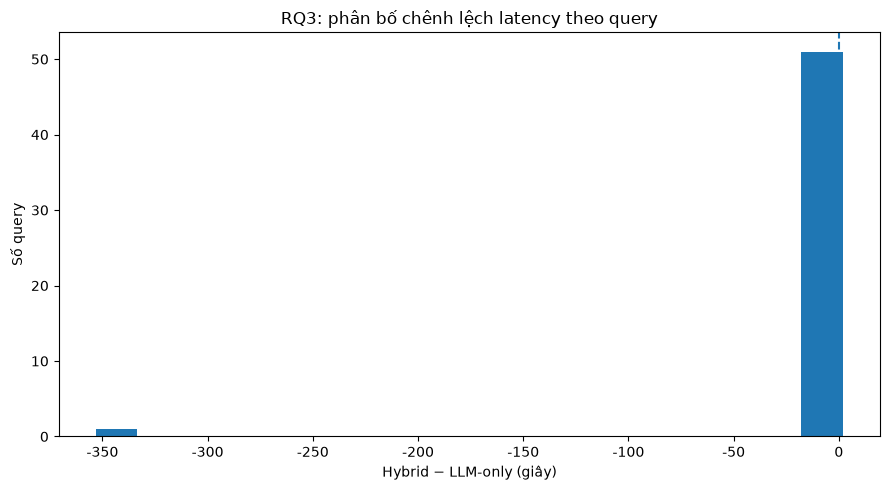

Số query ghép cặp: 52
Hybrid nhanh hơn: 50.0%
Median delta (giây): 0.037


In [28]:
paired_latency = independent.pivot_table(index="query_id", columns="system_label", values="latency_s", aggfunc="first")
if {"Hybrid", "LLM-only"}.issubset(paired_latency.columns):
    paired_latency = paired_latency.dropna(subset=["Hybrid", "LLM-only"])
    paired_latency["delta_hybrid_minus_llm_s"] = paired_latency["Hybrid"] - paired_latency["LLM-only"]
    delta = paired_latency["delta_hybrid_minus_llm_s"]
    fig, ax = plt.subplots()
    ax.hist(delta, bins=18)
    ax.axvline(0, linestyle="--")
    ax.set_title("RQ3: phân bố chênh lệch latency theo query")
    ax.set_xlabel("Hybrid − LLM-only (giây)")
    ax.set_ylabel("Số query")
    plt.tight_layout()
    plt.show()
    print("Số query ghép cặp:", len(delta))
    print("Hybrid nhanh hơn:", f"{(delta < 0).mean():.1%}")
    print("Median delta (giây):", round(delta.median(), 3))
else:
    print("Không đủ hai hệ thống để ghép cặp latency.")

### Biểu đồ 24 — Số lần thử gọi API thực tế

**Ý nghĩa:** với LLM-only dùng `api_attempts`; với Hybrid dùng `nlu_api_attempts`, theo protocol. Không dùng `llm_calls` thay cho attempts vì đó có thể là khái niệm khác trong pipeline.

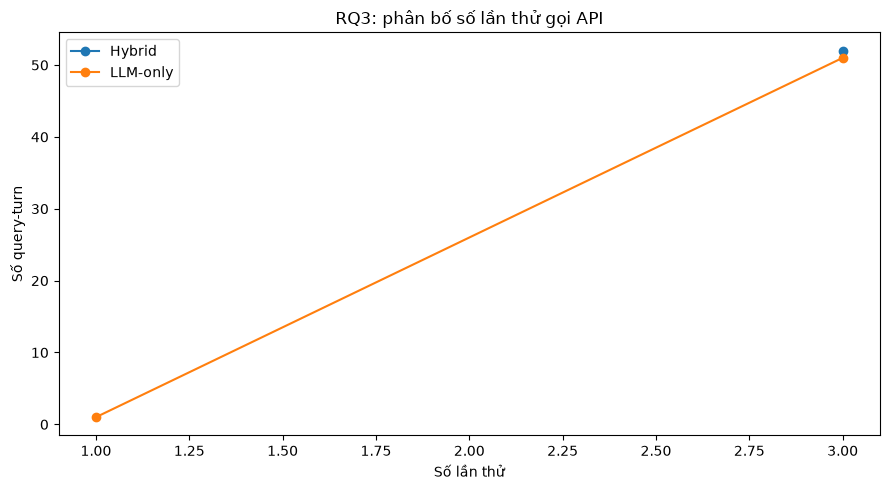

,count,mean,median,max
system_label,,,,
Hybrid,52,3.00,3.0,3.0
LLM-only,52,2.96,3.0,3.0


In [29]:
attempts = independent.copy()
attempts["attempts_metric"] = np.where(
    attempts["system"].eq("llm_only"),
    pd.to_numeric(attempts.get("api_attempts"), errors="coerce"),
    pd.to_numeric(attempts.get("nlu_api_attempts"), errors="coerce")
)
attempts = attempts.dropna(subset=["attempts_metric"])
if not attempts.empty:
    fig, ax = plt.subplots()
    for label, group in attempts.groupby("system_label"):
        vals = group["attempts_metric"].value_counts().sort_index()
        ax.plot(vals.index, vals.values, marker="o", label=label)
    ax.set_title("RQ3: phân bố số lần thử gọi API")
    ax.set_xlabel("Số lần thử")
    ax.set_ylabel("Số query-turn")
    ax.legend()
    plt.tight_layout()
    plt.show()
    display(attempts.groupby("system_label")["attempts_metric"].agg(["count", "mean", "median", "max"]).round(2))

### Biểu đồ 25 — Token đầu vào và đầu ra theo hệ thống

**Ý nghĩa:** so sánh lượng token được ghi trong log. Token lớn có thể làm tăng chi phí và thời gian, nhưng không thể kết luận hiệu quả chỉ dựa trên token mà bỏ qua chất lượng kết quả. Các ô thiếu token bị loại khỏi phép tính từng cột.

,input_tokens,output_tokens,thinking_tokens,total_tokens
system_label,,,,
Hybrid,1195.7,161.6,0.0,1357.3
LLM-only,232.7,206.2,17.5,456.4


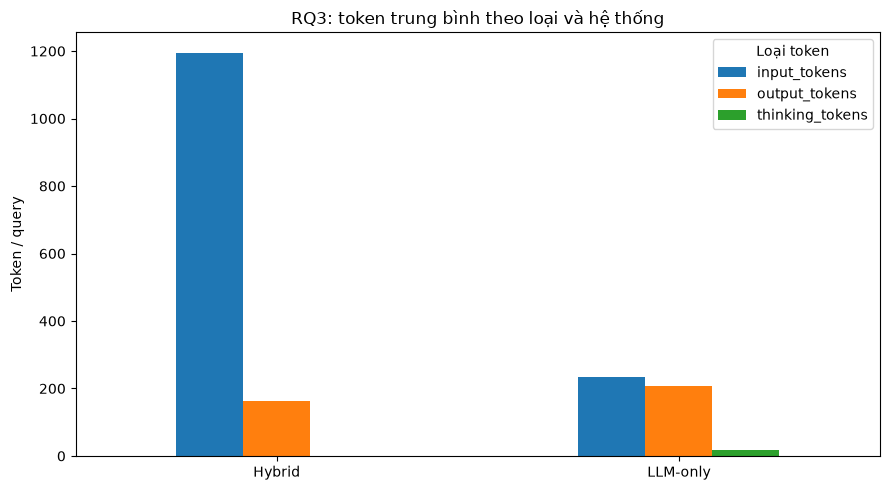

In [30]:
token_cols = [c for c in ["input_tokens", "output_tokens", "thinking_tokens", "total_tokens"] if c in independent.columns]
if token_cols:
    token_summary = independent.groupby("system_label")[token_cols].mean(numeric_only=True)
    display(token_summary.round(1))
    cols = [c for c in ["input_tokens", "output_tokens", "thinking_tokens"] if c in token_summary.columns]
    if cols:
        fig, ax = plt.subplots()
        token_summary[cols].plot(kind="bar", ax=ax)
        ax.set_title("RQ3: token trung bình theo loại và hệ thống")
        ax.set_ylabel("Token / query")
        ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=0)
        ax.legend(title="Loại token")
        plt.tight_layout()
        plt.show()
else:
    print("Không có cột token trong dataset này.")

### Biểu đồ 26 — Cơ cấu token của Hybrid và LLM-only

**Ý nghĩa:** biểu đồ cột chồng thể hiện token đầu vào, đầu ra và thinking token trung bình. Vì đây là giá trị trung bình, tổng chiều cao là tổng token trung bình nếu các thành phần cùng được ghi đầy đủ; thiếu dữ liệu cần được kiểm tra trước khi diễn giải.

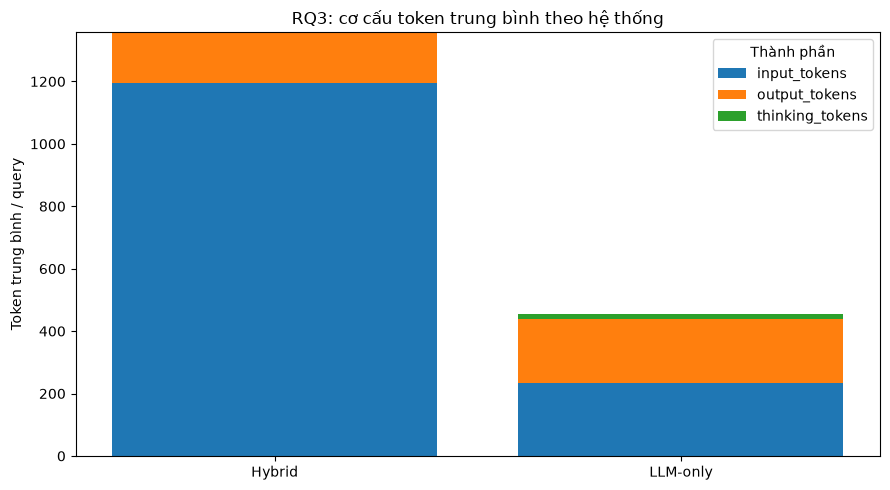

In [31]:
parts = [c for c in ["input_tokens", "output_tokens", "thinking_tokens"] if c in independent.columns]
if parts:
    mean_parts = independent.groupby("system_label")[parts].mean(numeric_only=True).fillna(0)
    fig, ax = plt.subplots()
    bottom = np.zeros(len(mean_parts))
    for col in parts:
        vals = mean_parts[col].values
        ax.bar(mean_parts.index, vals, bottom=bottom, label=col)
        bottom += vals
    ax.set_title("RQ3: cơ cấu token trung bình theo hệ thống")
    ax.set_ylabel("Token trung bình / query")
    ax.set_xlabel("")
    ax.legend(title="Thành phần")
    plt.tight_layout()
    plt.show()

### Biểu đồ 27 — Phân bố chi phí API ước tính trên mỗi query

**Ý nghĩa:** so sánh phân bố `estimated_api_cost_usd` được ghi trong log. Đây là chi phí ước tính dựa trên usage metadata và snapshot giá đã cấu hình, không phải hóa đơn thực tế. Chỉ dùng những dòng có giá trị chi phí hợp lệ.

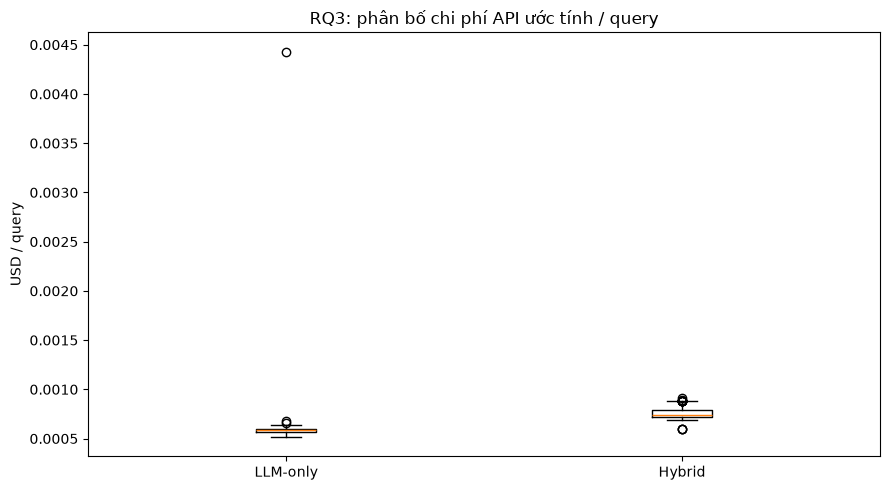

,count,mean,median,sum
system_label,,,,
Hybrid,52,0.000763,0.000745,0.039663
LLM-only,52,0.000658,0.000586,0.034228


In [32]:
cost = independent.dropna(subset=["estimated_api_cost_usd"]).copy()
cost = cost[cost["estimated_api_cost_usd"] >= 0]
if not cost.empty:
    fig, ax = plt.subplots()
    cost_groups = [g["estimated_api_cost_usd"].values for _, g in cost.groupby("system_label", sort=False)]
    cost_labels = [name for name, _ in cost.groupby("system_label", sort=False)]
    ax.boxplot(cost_groups, tick_labels=cost_labels, showfliers=True)
    ax.set_title("RQ3: phân bố chi phí API ước tính / query")
    ax.set_ylabel("USD / query")
    plt.tight_layout()
    plt.show()
    display(cost.groupby("system_label")["estimated_api_cost_usd"].agg(["count", "mean", "median", "sum"]).round(7))
else:
    print("Không có chi phí API ước tính hợp lệ trong các ca so sánh.")

### Biểu đồ 28 — Chi phí trung bình và chi phí mỗi khuyến nghị hoàn thành

**Ý nghĩa:** chi phí trung bình trên mỗi bản ghi không giống chi phí trên mỗi khuyến nghị hoàn thành. Biểu đồ này tính tổng chi phí chia cho số khuyến nghị có trạng thái hoàn thành theo định nghĩa trong notebook. Chỉ tính trên các bản ghi có chi phí ước tính; hãy nêu rõ mẫu số khi đưa số vào báo cáo.

,Chi phí trung bình/query (USD),Chi phí/khuyến nghị hoàn thành (USD),n có cost,n hoàn thành
Hệ thống,,,,
Hybrid,0.000763,0.000763,52,52
LLM-only,0.000658,0.000658,52,52


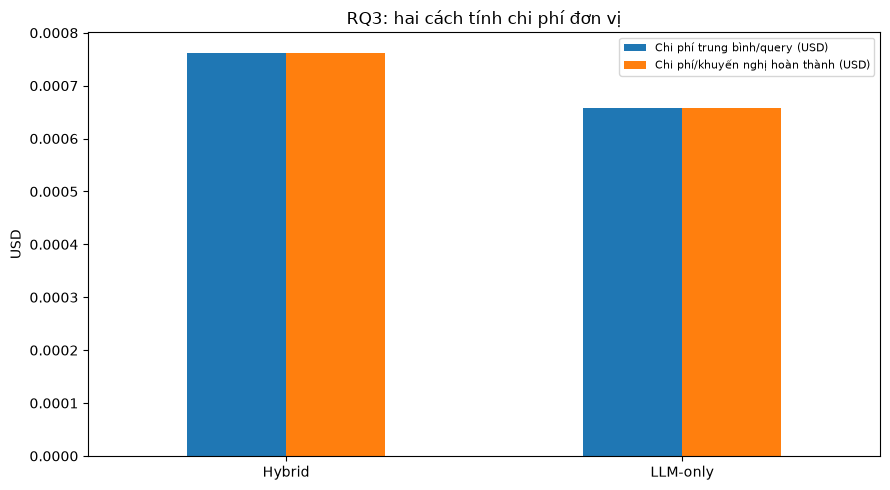

In [33]:
if not cost.empty:
    cost["completed_recommendation"] = np.where(
        cost["system"].eq("llm_only"),
        cost["status"].eq("COMPLETED"),
        cost["status"].isin(["OPTIMAL", "FEASIBLE", "RELAXED"])
    )
    rows = []
    for name, g in cost.groupby("system_label"):
        completed_n = int(g["completed_recommendation"].sum())
        total_cost = g["estimated_api_cost_usd"].sum()
        rows.append({"Hệ thống": name,
                     "Chi phí trung bình/query (USD)": g["estimated_api_cost_usd"].mean(),
                     "Chi phí/khuyến nghị hoàn thành (USD)": total_cost / completed_n if completed_n else np.nan,
                     "n có cost": len(g), "n hoàn thành": completed_n})
    cost_summary = pd.DataFrame(rows).set_index("Hệ thống")
    display(cost_summary.round(7))
    plot_cols = ["Chi phí trung bình/query (USD)", "Chi phí/khuyến nghị hoàn thành (USD)"]
    fig, ax = plt.subplots()
    cost_summary[plot_cols].plot(kind="bar", ax=ax)
    ax.set_title("RQ3: hai cách tính chi phí đơn vị")
    ax.set_ylabel("USD")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

### Biểu đồ 29 — Mối quan hệ giữa token và latency

**Ý nghĩa:** biểu đồ phân tán cho biết query dùng nhiều token có thường đi kèm latency cao hơn hay không. Mối tương quan không chứng minh quan hệ nhân quả; retry, rate limit, model fallback và độ dài prompt đều có thể ảnh hưởng.

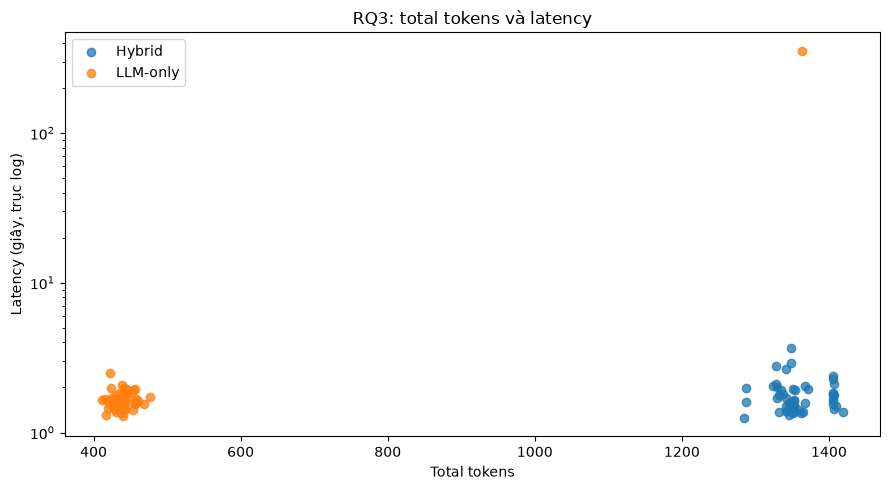

In [34]:
scatter_df = independent.copy()
scatter_df["total_tokens"] = pd.to_numeric(scatter_df.get("total_tokens"), errors="coerce")
scatter_df = scatter_df.dropna(subset=["total_tokens", "latency_s"])
fig, ax = plt.subplots()
for label, group in scatter_df.groupby("system_label"):
    ax.scatter(group["total_tokens"], group["latency_s"], label=label, alpha=0.75)
ax.set_yscale("log")
ax.set_title("RQ3: total tokens và latency")
ax.set_xlabel("Total tokens")
ax.set_ylabel("Latency (giây, trục log)")
ax.legend()
plt.tight_layout()
plt.show()

### Biểu đồ 30 — Latency theo nhóm nhu cầu

**Ý nghĩa:** xem có nhóm truy vấn nào thường chậm hơn. Các nhóm có số lượng mẫu nhỏ hoặc outlier lớn có thể làm thống kê dao động; dùng biểu đồ này để tìm điểm cần điều tra, không tự kết luận nguyên nhân.

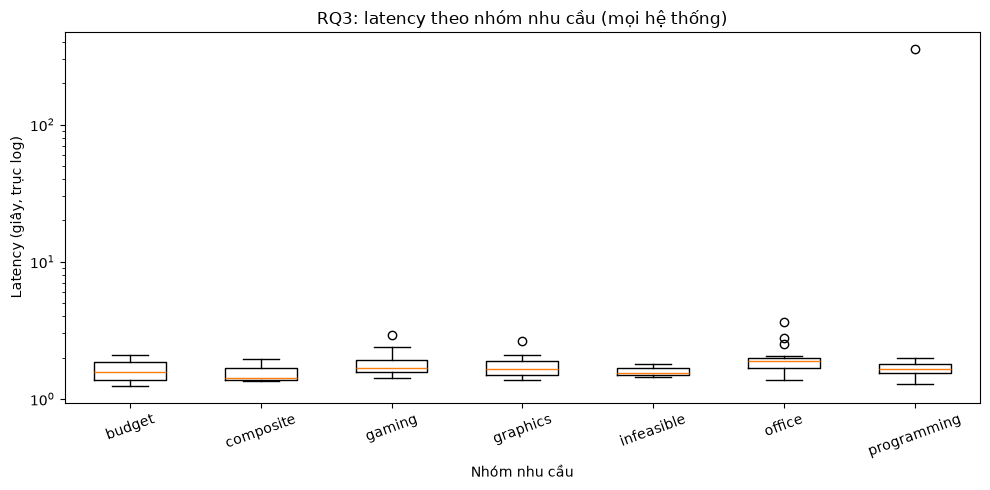

In [35]:
lat_cat = independent.dropna(subset=["latency_s"]).copy()
lat_cat = lat_cat[lat_cat["latency_s"] > 0]
if not lat_cat.empty:
    categories = sorted(lat_cat["category"].fillna("unknown").unique())
    fig, ax = plt.subplots(figsize=(10, 5))
    for i, category in enumerate(categories, start=1):
        vals = lat_cat.loc[lat_cat["category"].eq(category), "latency_s"].dropna()
        if len(vals):
            ax.boxplot(vals, positions=[i], widths=0.55, showfliers=True)
    ax.set_xticks(range(1, len(categories) + 1), labels=categories, rotation=20)
    ax.set_yscale("log")
    ax.set_title("RQ3: latency theo nhóm nhu cầu (mọi hệ thống)")
    ax.set_ylabel("Latency (giây, trục log)")
    ax.set_xlabel("Nhóm nhu cầu")
    plt.tight_layout()
    plt.show()

### Biểu đồ 31 — Model được dùng sau retry/fallback

**Ý nghĩa:** cho biết model nào thực sự tạo ra kết quả theo log. Nếu một query thử nhiều model rồi mới thành công, biểu đồ này thường phản ánh model thành công cuối cùng; cần xem thêm `api_attempts` và `api_errors` khi phân tích outlier.

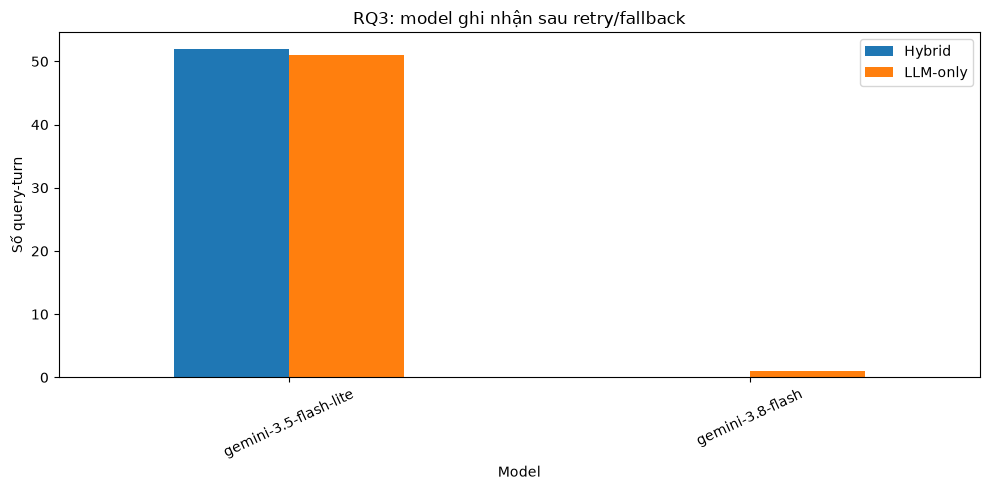

In [36]:
model_col = "api_model" if "api_model" in llm_only.columns else None
hybrid_model_col = "nlu_api_model" if "nlu_api_model" in hybrid.columns else None
model_frames = []
if model_col:
    model_frames.append(pd.DataFrame({"Hệ thống": "LLM-only", "Model": llm_only[model_col].fillna("unknown")}))
if hybrid_model_col:
    model_frames.append(pd.DataFrame({"Hệ thống": "Hybrid", "Model": hybrid[hybrid["scope"].ne("multiturn")][hybrid_model_col].fillna("unknown")}))
if model_frames:
    models = pd.concat(model_frames, ignore_index=True)
    model_counts = pd.crosstab(models["Model"], models["Hệ thống"])
    fig, ax = plt.subplots(figsize=(10, 5))
    model_counts.plot(kind="bar", ax=ax)
    ax.set_title("RQ3: model ghi nhận sau retry/fallback")
    ax.set_xlabel("Model")
    ax.set_ylabel("Số query-turn")
    ax.tick_params(axis="x", rotation=25)
    ax.legend()
    plt.tight_layout()
    plt.show()

### Biểu đồ 32 — Tương quan giữa latency, token, attempts và chi phí

**Ý nghĩa:** ma trận tương quan giúp rà soát biến vận hành nào biến thiên cùng nhau. Tương quan chỉ mô tả quan hệ tuyến tính trên các bản ghi có đủ dữ liệu; không phải bằng chứng rằng một biến gây ra biến kia.

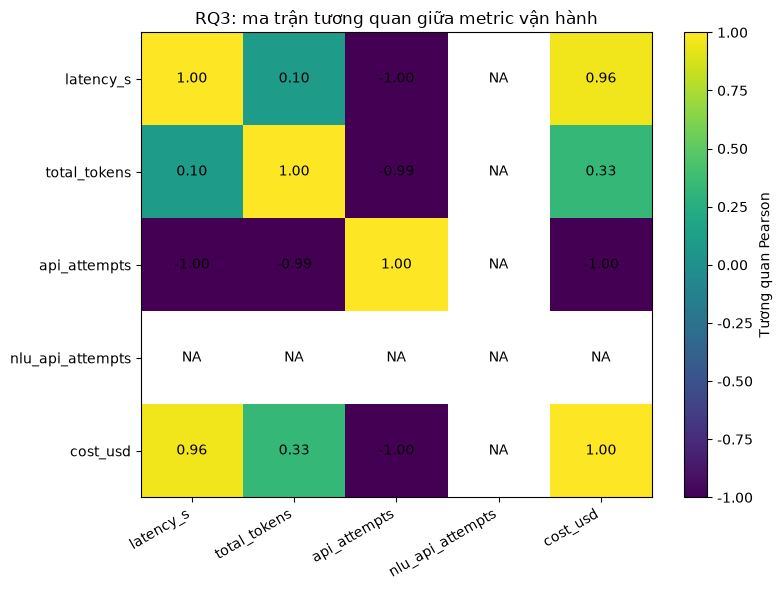

In [37]:
corr_cols = [c for c in ["latency_s", "total_tokens", "api_attempts", "nlu_api_attempts", "estimated_api_cost_usd"] if c in independent.columns]
corr_data = independent[corr_cols].copy()
for c in corr_cols:
    corr_data[c] = pd.to_numeric(corr_data[c], errors="coerce")
corr_data = corr_data.rename(columns={"latency_s": "latency_s", "total_tokens": "total_tokens",
                                      "api_attempts": "api_attempts", "nlu_api_attempts": "nlu_api_attempts",
                                      "estimated_api_cost_usd": "cost_usd"})
if corr_data.shape[1] >= 2:
    corr = corr_data.corr(numeric_only=True)
    fig, ax = plt.subplots(figsize=(8, 6))
    im = ax.imshow(corr.values, vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(len(corr.columns)), labels=corr.columns, rotation=30, ha="right")
    ax.set_yticks(range(len(corr.index)), labels=corr.index)
    ax.set_title("RQ3: ma trận tương quan giữa metric vận hành")
    for i in range(corr.shape[0]):
        for j in range(corr.shape[1]):
            val = corr.iloc[i, j]
            ax.text(j, i, f"{val:.2f}" if pd.notna(val) else "NA", ha="center", va="center")
    fig.colorbar(im, ax=ax, label="Tương quan Pearson")
    plt.tight_layout()
    plt.show()

## Biểu đồ bổ sung — Phân tích đầu ra tối ưu hóa

### Biểu đồ 33 — Phân bố relevance score theo loại khuyến nghị

**Ý nghĩa:** dùng các đề xuất Top-3 được ghi trong `optimization_details` của Hybrid để xem điểm relevance phân bố ra sao giữa Best Match, Budget Alternative và Performance Alternative. Đây là phân bố điểm nội bộ của solver, không phải đánh giá độc lập về mức độ hài lòng của người dùng.

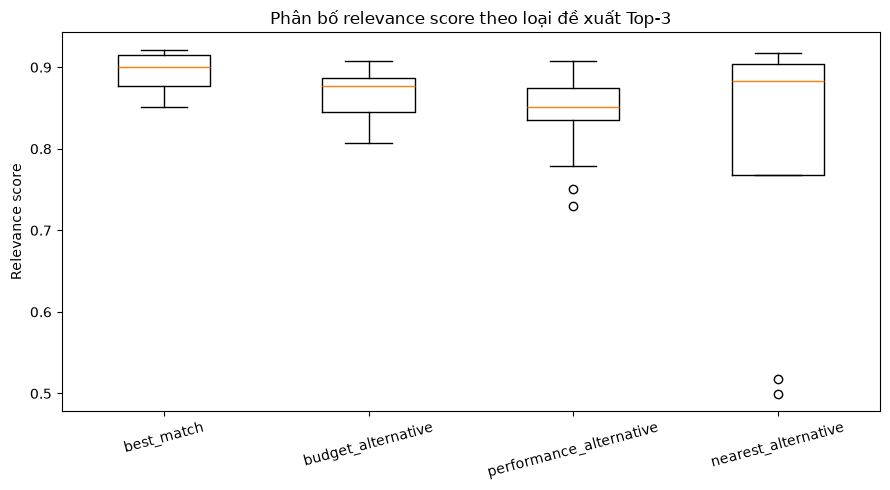

In [38]:
recommendation_rows = []
if "optimization_details" in hybrid.columns:
    for r in hybrid.to_dict("records"):
        details = r.get("optimization_details")
        if isinstance(details, dict):
            for rec in details.get("recommendations", []) or []:
                recommendation_rows.append({
                    "query_id": r.get("query_id"),
                    "scope": r.get("evaluation_scope"),
                    "type": rec.get("type", "unknown"),
                    "rank": rec.get("rank"),
                    "relevance_score": rec.get("relevance_score"),
                    "utility_score": rec.get("utility_score"),
                    "price": rec.get("price")
                })
recs = pd.DataFrame(recommendation_rows)
if not recs.empty and "relevance_score" in recs.columns:
    recs["relevance_score"] = pd.to_numeric(recs["relevance_score"], errors="coerce")
    type_order = list(recs["type"].dropna().unique())
    vals = [recs.loc[recs["type"].eq(t), "relevance_score"].dropna().values for t in type_order]
    fig, ax = plt.subplots()
    ax.boxplot(vals, tick_labels=type_order, showfliers=True)
    ax.set_title("Phân bố relevance score theo loại đề xuất Top-3")
    ax.set_ylabel("Relevance score")
    ax.tick_params(axis="x", rotation=15)
    plt.tight_layout()
    plt.show()
else:
    print("Không có recommendations trong optimization_details.")

### Biểu đồ 34 — Số ứng viên sau lọc theo nhóm nhu cầu

**Ý nghĩa:** giúp xem nhóm nhu cầu nào thường để lại nhiều hay ít ứng viên. Số ứng viên nhỏ không tự động là xấu: các điều kiện chặt có thể khiến tập hợp lệ nhỏ. Cần đọc cùng với tính khả thi và mức khớp yêu cầu.

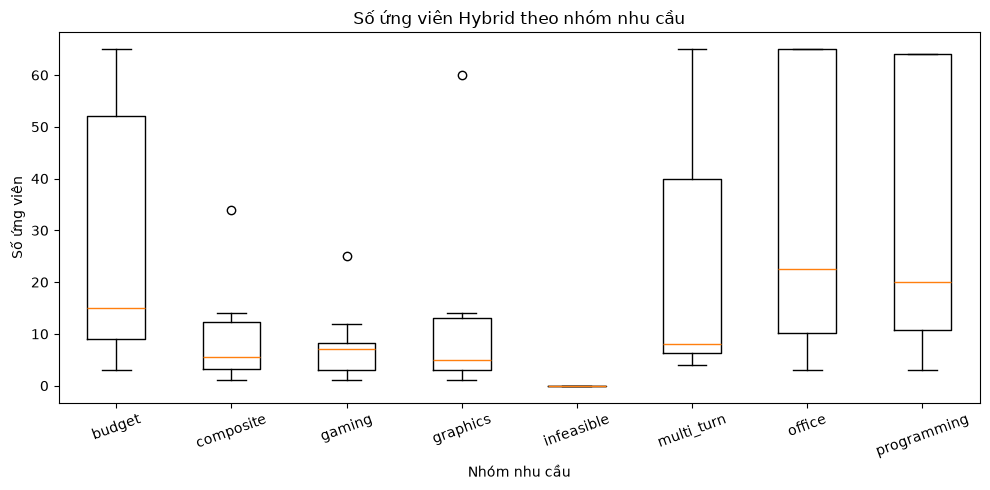

In [39]:
cand_cat = hybrid.copy()
cand_cat["candidate_count"] = pd.to_numeric(cand_cat["candidate_count"], errors="coerce")
cats = sorted(cand_cat["category"].fillna("unknown").unique())
fig, ax = plt.subplots(figsize=(10, 5))
box_data = [cand_cat.loc[cand_cat["category"].eq(cat), "candidate_count"].dropna().values for cat in cats]
ax.boxplot(box_data, tick_labels=cats, showfliers=True)
ax.set_title("Số ứng viên Hybrid theo nhóm nhu cầu")
ax.set_ylabel("Số ứng viên")
ax.set_xlabel("Nhóm nhu cầu")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## Bảng chẩn đoán — Các query có latency lớn nhất

Biểu đồ tổng quan cần đi cùng việc kiểm tra từng trường hợp chậm. Bảng dưới đây giữ lại các query có latency lớn nhất để bạn kiểm tra `api_attempts`, model, lỗi API và query gốc. Không loại outlier chỉ vì nó làm kết quả trung bình xấu đi.

In [40]:
diagnostic_cols = [c for c in ["query_id", "system_label", "scope", "category", "raw_query", "status",
                                 "latency_s", "api_attempts", "nlu_api_attempts", "api_model", "nlu_api_model",
                                 "estimated_api_cost_usd"] if c in df.columns]
display(df.sort_values("latency_s", ascending=False)[diagnostic_cols].head(15))

,query_id,system_label,scope,category,raw_query,status,latency_s,api_attempts,nlu_api_attempts,api_model,nlu_api_model,estimated_api_cost_usd
16,P01,LLM-only,main,programming,Tìm laptop lập trình tầm 20 triệu.,COMPLETED,354.69685,1.0,NaN,gemini-3.8-flash,NaN,0.004430
9,O05,Hybrid,main,office,"Tìm laptop office dưới 25 triệu, pin ít nhất 8 giờ.",OPTIMAL,3.66236,NaN,3.0,NaN,gemini-3.5-flash-lite,0.000739
43,G06,Hybrid,main,gaming,"Tìm laptop FPS dưới 30 triệu, nặng không quá 2kg.",OPTIMAL,2.93524,NaN,3.0,NaN,gemini-3.5-flash-lite,0.000739
1,O01,Hybrid,main,office,Tư vấn laptop văn phòng giá rẻ tầm 15 triệu.,OPTIMAL,2.80051,NaN,3.0,NaN,gemini-3.5-flash-lite,0.000693
49,D01,Hybrid,main,graphics,Tư vấn laptop đồ họa dưới 30 triệu có card rời.,OPTIMAL,2.66025,NaN,3.0,NaN,gemini-3.5-flash-lite,0.000723
0,O01,LLM-only,main,office,Tư vấn laptop văn phòng giá rẻ tầm 15 triệu.,COMPLETED,2.49384,3.0,NaN,gemini-3.5-flash-lite,NaN,0.000547
47,G08,Hybrid,main,gaming,Tìm laptop gaming dưới 35 triệu có RTX 4070.,OPTIMAL,2.39804,NaN,3.0,NaN,gemini-3.5-flash-lite,0.000884
39,G04,Hybrid,main,gaming,Tìm laptop game khoảng 24 triệu có RTX 4050.,OPTIMAL,2.29295,NaN,3.0,NaN,gemini-3.5-flash-lite,0.000884
104,M01-T1,Hybrid,multiturn,multi_turn,Tôi cần laptop lập trình tầm 20 triệu.,OPTIMAL,2.16466,NaN,3.0,NaN,gemini-3.5-flash-lite,0.000600
109,M02-T3,Hybrid,multiturn,multi_turn,Tư vấn laptop văn phòng giá rẻ tầm 15 triệu.,OPTIMAL,2.15030,NaN,3.0,NaN,gemini-3.5-flash-lite,0.000693


## Gợi ý chọn biểu đồ đưa vào báo cáo

Không nhất thiết đưa tất cả biểu đồ vào slide. Nên chọn biểu đồ trả lời trực tiếp từng RQ:

- **RQ1:** Biểu đồ 4 (exact extraction), 7 (feasibility confusion matrix), 8 hoặc 9 (candidate count), 10 (multi-turn action).
- **RQ2:** Biểu đồ 13–16 cho log hệ thống; ưu tiên Biểu đồ 20 nếu đã tạo được đánh giá độc lập theo catalog. Dùng Biểu đồ 17–19 để trình bày riêng xác minh ngoài của LLM-only.
- **RQ3:** Biểu đồ 21–23 (latency và outlier), 24 (API attempts), 25–28 (token/cost).

Khi viết kết luận, ghi rõ mẫu số và phạm vi. Ví dụ: “trên 44 ca khả thi độc lập” khác với “trên toàn bộ 60 lượt Hybrid”. Không gọi `OUT_OF_CATALOG` là hallucination nếu chưa có xác minh độc lập.